In [2]:
# 🎬 YouTube Trending Video Analysis
### Predicting Viral Content Using NLP, Clustering, and XGBoost

---

## 📌 Project Objective

This project investigates what makes a YouTube video go viral on the US trending page.
Using a dataset of over 40,000 trending video records, we build a complete machine learning 
pipeline that goes from raw CSV data to a trained classifier capable of predicting whether 
a video will trend for 3 or more days — a threshold we define as **"viral."**

The project was built end-to-end: data exploration, SQL analysis, NLP feature engineering, 
unsupervised clustering, supervised classification, and model explainability using SHAP.

---

## 📦 Dataset

| Property | Details |
|---|---|
| Source | Kaggle — YouTube Trending Video Dataset (datasnaek/youtube-new) |
| Region | United States (USvideos.csv) |
| Size | ~40,949 rows × 16 columns |
| Coverage | Daily trending snapshots across multiple months |

**Key columns used:**

- `title` — video title (cleaned and TF-IDF vectorized)
- `tags` — creator-defined tags (cleaned and combined with title)
- `views`, `likes`, `dislikes`, `comment_count` — engagement metrics
- `category_id` — YouTube content category (mapped to readable names)
- `trending_date` — date the video appeared on the trending page

---

## 🔬 Methodology

The project follows six sequential stages:

| Stage | Technique | Output |
|---|---|---|
| 1. Data Exploration | Pandas, Matplotlib, Seaborn | 4 EDA charts |
| 2. SQL Analysis | SQLite + Pandas | 3 query result tables |
| 3. Target Engineering | Trending day count threshold | `is_viral` binary column |
| 4. NLP Feature Engineering | Text cleaning + TF-IDF (100 features) + 11 numeric features | Feature matrix X (111 columns) |
| 5. Clustering | K-Means (k=4, elbow method) | 4 named video clusters |
| 6. Classification & Evaluation | XGBoost + SHAP | Trained model + feature importance |

---

## 📊 Key Results

| Metric | Value |
|---|---|
| Overall Accuracy | 87.86% |
| AUC Score | 0.8725 |
| Viral Videos F1 Score | 0.93 |
| Best Cluster (avg views) | 🚀 Viral Giants — 99M avg views |
| Top Predictive Feature | TF-IDF word: "audio" (SHAP = 0.778) |
| Training Set Size | ~32,000 rows |
| Total Features Used | 111 (100 TF-IDF + 11 numeric) |

---

## 🛠️ Tools and Libraries

`Python 3.14` · `Pandas` · `NumPy` · `Scikit-learn` · `XGBoost` · `SHAP` · 
`Matplotlib` · `Seaborn` · `SQLite3` · `SciPy` · `Joblib`

---

*Project by Suparna Deshmukh · YouTube Trending Dataset · US Region*

✅ Libraries loaded and chart settings applied!


In [1]:
import os

# create the charts folder if it doesn't already exist
# exist_ok=True means it won't throw an error if the folder is already there
os.makedirs("/Users/suparna_deshmukh/projects/youtube-project/charts", exist_ok=True)

print("✅ Charts folder ready!")

✅ Charts folder ready!


In [3]:
# ── CHART 1: BAR CHART OF TRENDING VIDEOS BY CATEGORY ────────────────────────

# the dataset has a 'category_id' column which is a number (e.g. 24 = Entertainment)
# we need to map those numbers to actual category names using a dictionary
# these are the official YouTube category IDs for the US region
category_map = {
    1:  "Film & Animation",
    2:  "Autos & Vehicles",
    10: "Music",
    15: "Pets & Animals",
    17: "Sports",
    18: "Short Movies",
    19: "Travel & Events",
    20: "Gaming",
    21: "Videoblogging",
    22: "People & Blogs",
    23: "Comedy",
    24: "Entertainment",
    25: "News & Politics",
    26: "Howto & Style",
    27: "Education",
    28: "Science & Technology",
    29: "Nonprofits & Activism",
    30: "Movies",
    43: "Shows",
    44: "Trailers"
}

# create a new column called 'category_name' by replacing each number with its label
# .map() goes through every row and swaps the number for the matching name
# if a number isn't in our dictionary, it returns NaN (blank) — fillna handles that
df['category_name'] = df['category_id'].map(category_map).fillna("Unknown")

# count how many videos exist per category
# value_counts() counts occurrences and sorts from most to least
category_counts = df['category_name'].value_counts()

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

# figsize sets the width and height of the chart in inches
fig, ax = plt.subplots(figsize=(14, 6))

# sns.barplot draws the bar chart
# x = the category names, y = the counts
# ax=ax tells seaborn which canvas to draw on
sns.barplot(
    x=category_counts.index,   # category names on the x-axis
    y=category_counts.values,  # video counts on the y-axis
    ax=ax
)

# rotate x-axis labels 45 degrees so they don't overlap each other
# ha='right' aligns the rotated text neatly
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# add a title and axis labels
ax.set_title("Trending Videos by Category", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Category", fontsize=12)
ax.set_ylabel("Number of Trending Videos", fontsize=12)

# tight_layout adjusts spacing so nothing gets cut off
plt.tight_layout()

# save the chart as a PNG file into your charts folder
# dpi=150 sets the image resolution (higher = sharper)
plt.savefig(f"{CHARTS_DIR}/01_trending_by_category.png", dpi=150)

# display the chart inside the notebook
plt.show()

print("✅ Chart 1 saved!")

NameError: name 'df' is not defined

In [4]:
import pandas as pd
import os

# reload the dataset from scratch
data_path = "/Users/suparna_deshmukh/projects/youtube-project/data/raw/USvideos.csv"
df = pd.read_csv(data_path, encoding='latin-1')

print("✅ df reloaded!")
print(f"Shape: {df.shape}")
print(df.head(2))

✅ df reloaded!
Shape: (40949, 16)
      video_id trending_date  \
0  2kyS6SvSYSE      17.14.11   
1  1ZAPwfrtAFY      17.14.11   

                                               title    channel_title  \
0                 WE WANT TO TALK ABOUT OUR MARRIAGE     CaseyNeistat   
1  The Trump Presidency: Last Week Tonight with J...  LastWeekTonight   

   category_id              publish_time  \
0           22  2017-11-13T17:13:01.000Z   
1           24  2017-11-13T07:30:00.000Z   

                                                tags    views  likes  \
0                                    SHANtell martin   748374  57527   
1  last week tonight trump presidency|"last week ...  2418783  97185   

   dislikes  comment_count                                  thumbnail_link  \
0      2966          15954  https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg   
1      6146          12703  https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg   

   comments_disabled  ratings_disabled  video_error_or_removed  

/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/830590850.py:54: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


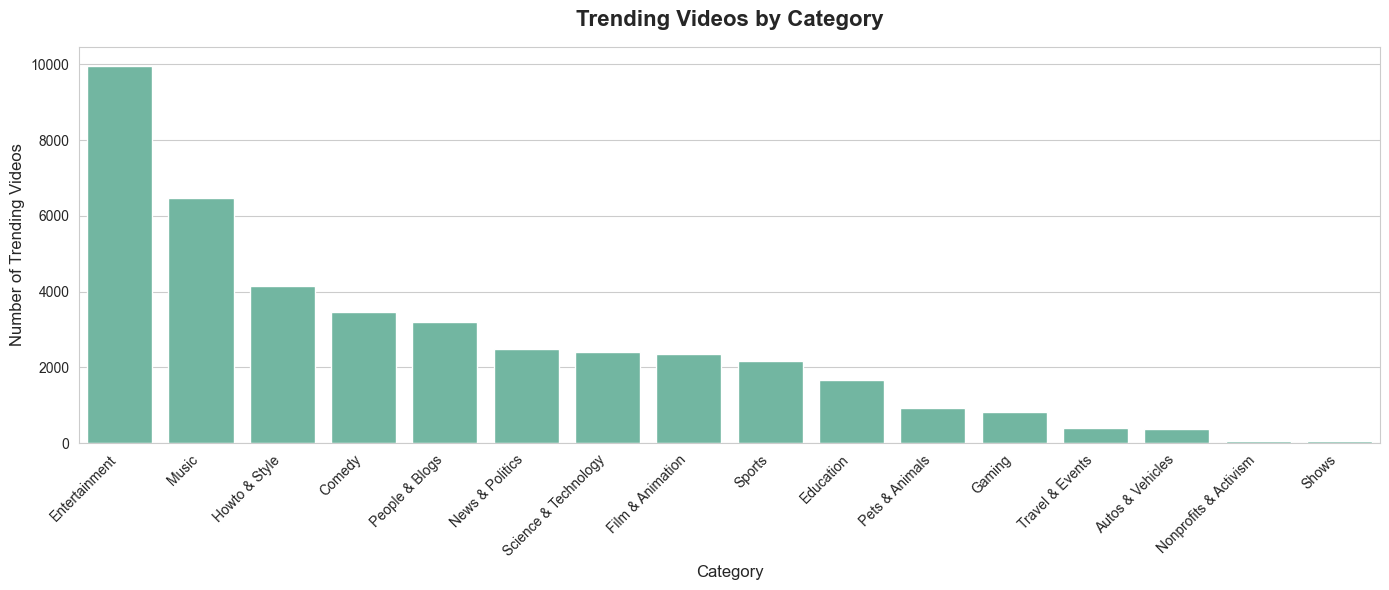

✅ Chart 1 saved!


In [5]:
# ── CHART 1: BAR CHART OF TRENDING VIDEOS BY CATEGORY ────────────────────────

# the dataset has a 'category_id' column which is a number (e.g. 24 = Entertainment)
# we need to map those numbers to actual category names using a dictionary
# these are the official YouTube category IDs for the US region
category_map = {
    1:  "Film & Animation",
    2:  "Autos & Vehicles",
    10: "Music",
    15: "Pets & Animals",
    17: "Sports",
    18: "Short Movies",
    19: "Travel & Events",
    20: "Gaming",
    21: "Videoblogging",
    22: "People & Blogs",
    23: "Comedy",
    24: "Entertainment",
    25: "News & Politics",
    26: "Howto & Style",
    27: "Education",
    28: "Science & Technology",
    29: "Nonprofits & Activism",
    30: "Movies",
    43: "Shows",
    44: "Trailers"
}

# create a new column called 'category_name' by replacing each number with its label
# .map() goes through every row and swaps the number for the matching name
# if a number isn't in our dictionary, it returns NaN (blank) — fillna handles that
df['category_name'] = df['category_id'].map(category_map).fillna("Unknown")

# count how many videos exist per category
# value_counts() counts occurrences and sorts from most to least
category_counts = df['category_name'].value_counts()

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

# figsize sets the width and height of the chart in inches
fig, ax = plt.subplots(figsize=(14, 6))

# sns.barplot draws the bar chart
# x = the category names, y = the counts
# ax=ax tells seaborn which canvas to draw on
sns.barplot(
    x=category_counts.index,   # category names on the x-axis
    y=category_counts.values,  # video counts on the y-axis
    ax=ax
)

# rotate x-axis labels 45 degrees so they don't overlap each other
# ha='right' aligns the rotated text neatly
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# add a title and axis labels
ax.set_title("Trending Videos by Category", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Category", fontsize=12)
ax.set_ylabel("Number of Trending Videos", fontsize=12)

# tight_layout adjusts spacing so nothing gets cut off
plt.tight_layout()

# save the chart as a PNG file into your charts folder
# dpi=150 sets the image resolution (higher = sharper)
plt.savefig(f"{CHARTS_DIR}/01_trending_by_category.png", dpi=150)

# display the chart inside the notebook
plt.show()

print("✅ Chart 1 saved!")

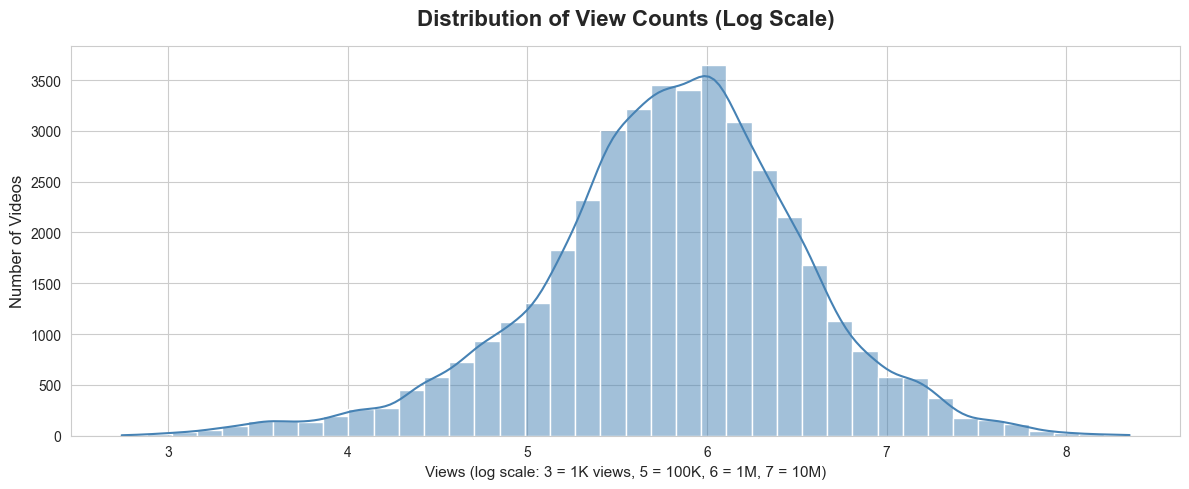

✅ Chart 2 saved!


In [6]:
# ── CHART 2: HISTOGRAM OF VIEW COUNTS ────────────────────────────────────────

# view counts vary enormously — some videos have 10,000 views, others have 100,000,000
# if we plot raw numbers, most bars will be squished near zero
# we use a log scale to spread the data out so we can actually see the shape

import numpy as np  # numpy lets us do math operations on entire columns at once

# create a new column with the log (base 10) of view count
# np.log10(1000) = 3, np.log10(1000000) = 6 — this compresses the big numbers
# we add 1 before the log to avoid errors on any zero values (log of 0 is undefined)
df['log_views'] = np.log10(df['views'] + 1)

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 5))

# sns.histplot draws a histogram — it groups values into bins and counts them
# bins=40 means we split the data into 40 groups
# kde=True draws a smooth curve on top showing the overall distribution shape
sns.histplot(
    df['log_views'],
    bins=40,
    kde=True,
    color='steelblue',
    ax=ax
)

ax.set_title("Distribution of View Counts (Log Scale)", fontsize=16, fontweight='bold', pad=15)

# explain the log scale on the x-axis with real examples
ax.set_xlabel("Views (log scale: 3 = 1K views, 5 = 100K, 6 = 1M, 7 = 10M)", fontsize=11)
ax.set_ylabel("Number of Videos", fontsize=12)

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/02_view_count_distribution.png", dpi=150)
plt.show()

print("✅ Chart 2 saved!")

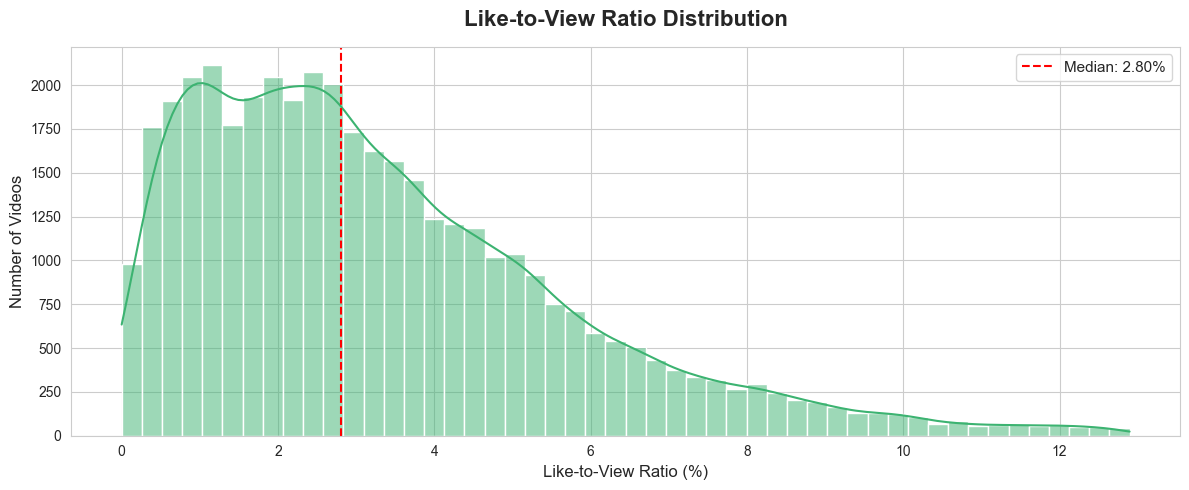

✅ Chart 3 saved! Median like ratio: 2.80%


In [7]:
# ── CHART 3: HISTOGRAM OF LIKE-TO-VIEW RATIO ─────────────────────────────────

# like-to-view ratio = likes divided by views
# it tells us what % of viewers actually liked the video
# a ratio of 0.05 means 5 out of every 100 viewers liked it

# we only calculate this for rows where views > 0
# to avoid dividing by zero, we filter those rows out first
df_filtered = df[df['views'] > 0].copy()

# calculate the ratio: likes divided by views
# multiply by 100 to express it as a percentage
df_filtered['like_ratio'] = (df_filtered['likes'] / df_filtered['views']) * 100

# some videos may have extreme outliers (ratio > 20% is very unusual)
# we clip the data at the 99th percentile to remove extreme outliers from the chart
upper_limit = df_filtered['like_ratio'].quantile(0.99)

# keep only rows where like_ratio is below the 99th percentile
df_plot = df_filtered[df_filtered['like_ratio'] <= upper_limit]

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    df_plot['like_ratio'],
    bins=50,
    kde=True,
    color='mediumseagreen',
    ax=ax
)

ax.set_title("Like-to-View Ratio Distribution", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Like-to-View Ratio (%)", fontsize=12)
ax.set_ylabel("Number of Videos", fontsize=12)

# add a vertical dashed line at the median ratio so we can see the typical value
median_ratio = df_plot['like_ratio'].median()

# axvline draws a vertical line at a specific x position
ax.axvline(median_ratio, color='red', linestyle='--', linewidth=1.5,
           label=f'Median: {median_ratio:.2f}%')

# show the legend so the red line label is visible
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/03_like_to_view_ratio.png", dpi=150)
plt.show()

print(f"✅ Chart 3 saved! Median like ratio: {median_ratio:.2f}%")

/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3957464700.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


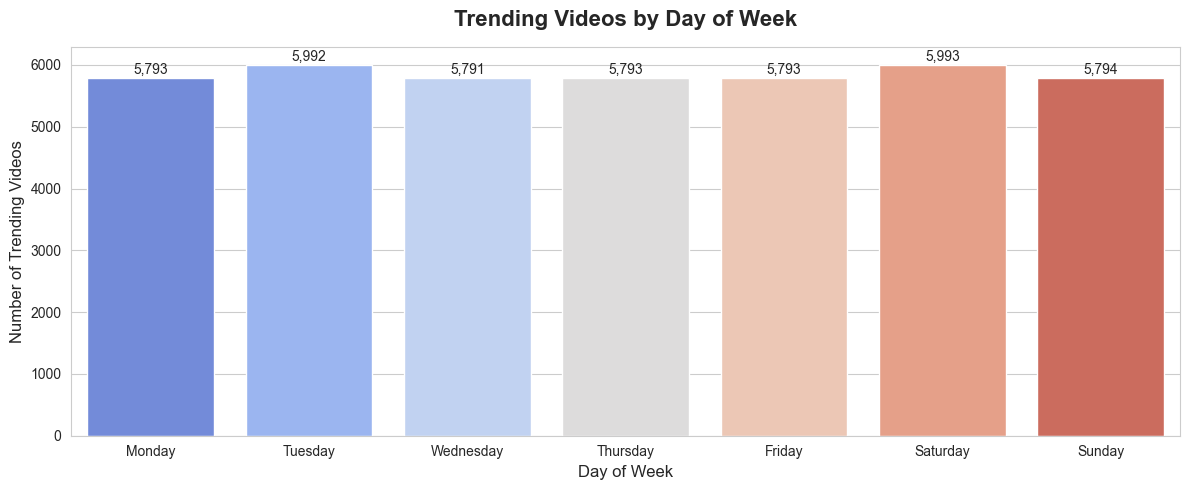

✅ Chart 4 saved!


In [8]:
# ── CHART 4: WHICH DAYS OF THE WEEK HAVE THE MOST TRENDING VIDEOS ─────────────

# the 'trending_date' column stores dates as text like '17.14.11' (YY.DD.MM format)
# we need to convert this text into a proper date so we can extract the day of week

# pd.to_datetime converts text into a real date Python can understand
# format='%y.%d.%m' tells pandas the exact structure: year.day.month
df['trending_date_parsed'] = pd.to_datetime(df['trending_date'], format='%y.%d.%m')

# .dt.day_name() extracts the full day name (Monday, Tuesday, etc.) from each date
df['day_of_week'] = df['trending_date_parsed'].dt.day_name()

# define the correct order for days of the week
# without this, bars would appear in random alphabetical order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# count how many trending videos appeared on each day
# reindex(day_order) forces the result to appear in Mon→Sun order
day_counts = df['day_of_week'].value_counts().reindex(day_order)

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 5))

# use a different color palette to make this chart visually distinct
colors = sns.color_palette("coolwarm", len(day_order))

sns.barplot(
    x=day_counts.index,   # days of the week on x-axis
    y=day_counts.values,  # video counts on y-axis
    palette=colors,
    ax=ax
)

ax.set_title("Trending Videos by Day of Week", fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel("Day of Week", fontsize=12)
ax.set_ylabel("Number of Trending Videos", fontsize=12)

# add the exact count number on top of each bar so it's easy to read
# ax.patches gives us each bar as a shape we can read the height from
for bar in ax.patches:
    ax.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of bar
        bar.get_height() + 20,               # y position: just above the bar
        f'{int(bar.get_height()):,}',        # the text: count with comma formatting
        ha='center', va='bottom', fontsize=10
    )

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/04_trending_by_day_of_week.png", dpi=150)
plt.show()

print("✅ Chart 4 saved!")

In [9]:
# list every file in your charts folder to confirm all 4 were saved
print("── CHARTS SAVED ──────────────────────────────")
for file in sorted(os.listdir(CHARTS_DIR)):
    print(f"  ✅ {file}")

── CHARTS SAVED ──────────────────────────────
  ✅ 01_trending_by_category.png
  ✅ 02_view_count_distribution.png
  ✅ 03_like_to_view_ratio.png
  ✅ 04_trending_by_day_of_week.png


In [10]:
# sqlite3 is built into Python — no installation needed
# it lets us create and query a database directly on your computer
import sqlite3

# pandas for working with the results as tables
import pandas as pd

# os for file path handling
import os

# define where the database file will be saved on your computer
# this creates a real .db file you can open later with DB Browser for SQLite
DB_PATH = "/Users/suparna_deshmukh/projects/youtube-project/data/sqlite/youtube_trending.db"

print("✅ Libraries imported!")
print(f"Database will be saved at: {DB_PATH}")

✅ Libraries imported!
Database will be saved at: /Users/suparna_deshmukh/projects/youtube-project/data/sqlite/youtube_trending.db


In [11]:
# if df is already loaded from a previous cell, you can skip this cell
# if you get a NameError on df anywhere, run this cell first

data_path = "/Users/suparna_deshmukh/projects/youtube-project/data/raw/USvideos.csv"
df = pd.read_csv(data_path, encoding='latin-1')

# map numeric category_id to human-readable names
category_map = {
    1: "Film & Animation", 2: "Autos & Vehicles", 10: "Music",
    15: "Pets & Animals", 17: "Sports", 18: "Short Movies",
    19: "Travel & Events", 20: "Gaming", 21: "Videoblogging",
    22: "People & Blogs", 23: "Comedy", 24: "Entertainment",
    25: "News & Politics", 26: "Howto & Style", 27: "Education",
    28: "Science & Technology", 29: "Nonprofits & Activism",
    30: "Movies", 43: "Shows", 44: "Trailers"
}
df['category_name'] = df['category_id'].map(category_map).fillna("Unknown")

print("✅ df loaded and ready!")
print(f"Shape: {df.shape}")

✅ df loaded and ready!
Shape: (40949, 17)


In [12]:
# ── LOAD DATAFRAME INTO SQLITE DATABASE ──────────────────────────────────────

# sqlite3.connect() creates a connection to the database file
# if the file doesn't exist yet, SQLite automatically creates it
conn = sqlite3.connect(DB_PATH)

# df.to_sql() writes the entire dataframe into the database as a table
# 'videos' is the name we give the table inside the database
# con=conn tells pandas which database to write to
# if_exists='replace' means: if the table already exists, overwrite it
# index=False means: don't write the pandas row numbers as a column
df.to_sql('videos', con=conn, if_exists='replace', index=False)

print("✅ Data loaded into SQLite successfully!")

# confirm by checking how many rows were written
# pd.read_sql() runs a SQL query and returns the result as a dataframe
row_count = pd.read_sql("SELECT COUNT(*) as total_rows FROM videos", conn)
print(f"Total rows in database: {row_count['total_rows'][0]:,}")

# show all columns that exist in the table
columns = pd.read_sql("PRAGMA table_info(videos)", conn)
print("\nColumns in the 'videos' table:")
print(columns[['name', 'type']].to_string(index=False))

✅ Data loaded into SQLite successfully!
Total rows in database: 40,949

Columns in the 'videos' table:
                  name    type
              video_id    TEXT
         trending_date    TEXT
                 title    TEXT
         channel_title    TEXT
           category_id INTEGER
          publish_time    TEXT
                  tags    TEXT
                 views INTEGER
                 likes INTEGER
              dislikes INTEGER
         comment_count INTEGER
        thumbnail_link    TEXT
     comments_disabled INTEGER
      ratings_disabled INTEGER
video_error_or_removed INTEGER
           description    TEXT
         category_name    TEXT


In [13]:
# ── SQL QUERY 1: TOP 10 CATEGORIES BY AVERAGE VIEWS ──────────────────────────

# SQL (Structured Query Language) is used to ask questions about data in a database
# think of it like asking Excel to filter and summarize rows for you

query_1 = """
    SELECT
        category_name,

        -- COUNT(*) counts how many rows exist for each category
        COUNT(*) AS total_videos,

        -- AVG() calculates the average of a column
        -- ROUND(..., 0) rounds to 0 decimal places
        ROUND(AVG(views), 0) AS avg_views,

        -- MAX() finds the highest value in a column
        ROUND(MAX(views), 0) AS max_views,

        -- MIN() finds the lowest value
        ROUND(MIN(views), 0) AS min_views

    FROM videos

    -- GROUP BY means: do these calculations separately for each category
    -- without GROUP BY, it would calculate one number for the entire table
    GROUP BY category_name

    -- ORDER BY sorts results — DESC means highest first
    ORDER BY avg_views DESC

    -- LIMIT 10 means: only return the top 10 rows
    LIMIT 10
"""

# pd.read_sql() sends the query to the database and returns results as a dataframe
result_1 = pd.read_sql(query_1, conn)

# format the number columns with commas for readability (e.g. 1,000,000)
# applymap applies a formatting function to every cell in those columns
for col in ['avg_views', 'max_views', 'min_views']:
    result_1[col] = result_1[col].apply(lambda x: f"{int(x):,}")

print("━" * 60)
print("  TOP 10 CATEGORIES BY AVERAGE VIEWS")
print("━" * 60)

# to_string(index=False) prints the table without the row numbers on the left
print(result_1.to_string(index=False))
print("━" * 60)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  TOP 10 CATEGORIES BY AVERAGE VIEWS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
        category_name  total_videos avg_views   max_views min_views
                Music          6472 6,201,003 225,211,923     1,591
     Film & Animation          2345 3,106,250  54,863,912       943
Nonprofits & Activism            57 2,963,884  24,286,474     1,456
               Gaming           817 2,620,831  16,935,442     1,237
        Entertainment          9964 2,067,883 149,376,127       798
               Sports          2174 2,025,969  29,090,799       658
       People & Blogs          3210 1,531,835  56,111,957       884
               Comedy          3457 1,480,308  29,178,096     1,807
 Science & Technology          2401 1,452,627  42,799,458       983
     Autos & Vehicles           384 1,355,965  25,244,097     2,860
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


In [14]:
# ── SQL QUERY 2: AVERAGE ENGAGEMENT RATE PER CATEGORY ────────────────────────

# engagement rate = (likes + dislikes + comment_count) / views * 100
# it tells us how actively viewers interacted with videos, as a percentage
# a high engagement rate means viewers didn't just watch — they reacted

query_2 = """
    SELECT
        category_name,

        COUNT(*) AS total_videos,

        -- calculate engagement rate inside the SQL query itself
        -- CAST(... AS FLOAT) converts the number to a decimal before dividing
        -- without CAST, SQL integer division would round everything to 0
        ROUND(
            AVG(
                CAST(likes + dislikes + comment_count AS FLOAT)
                / NULLIF(views, 0)  -- NULLIF prevents divide-by-zero errors
                * 100               -- multiply by 100 to get a percentage
            ), 4
        ) AS avg_engagement_rate_pct,

        -- also show average likes and comments separately for context
        ROUND(AVG(likes), 0)         AS avg_likes,
        ROUND(AVG(comment_count), 0) AS avg_comments

    FROM videos

    -- only include rows where views is greater than 0
    -- videos with 0 views would skew the engagement calculation
    WHERE views > 0

    GROUP BY category_name

    ORDER BY avg_engagement_rate_pct DESC
"""

result_2 = pd.read_sql(query_2, conn)

# format number columns with commas
for col in ['avg_likes', 'avg_comments']:
    result_2[col] = result_2[col].apply(lambda x: f"{int(x):,}")

# add a % symbol to the engagement rate column
result_2['avg_engagement_rate_pct'] = result_2['avg_engagement_rate_pct'].apply(
    lambda x: f"{x:.4f}%"
)

print("━" * 70)
print("  AVERAGE ENGAGEMENT RATE PER CATEGORY")
print("  (Engagement = Likes + Dislikes + Comments) / Views × 100")
print("━" * 70)
print(result_2.to_string(index=False))
print("━" * 70)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  AVERAGE ENGAGEMENT RATE PER CATEGORY
  (Engagement = Likes + Dislikes + Comments) / Views × 100
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
        category_name  total_videos avg_engagement_rate_pct avg_likes avg_comments
                Music          6472                 5.2686%   218,918       19,360
        Howto & Style          4146                 5.2218%    39,286        5,584
               Comedy          3457                 5.0630%    62,582        6,522
Nonprofits & Activism            57                 4.9175%   259,924       84,365
       People & Blogs          3210                 4.8676%    58,136        7,719
               Gaming           817                 4.7295%    84,502       18,042
            Education          1656                 4.3549%    29,745        3,286
       Pets & Animals           920                 3.8239%    21,055        2,892
 Science & Te

In [15]:
# ── SQL QUERY 3: TOP 20 CHANNELS BY TOTAL TRENDING DAYS ──────────────────────

# each row in the dataset = one video on one trending day
# if a video trends for 10 days, it appears 10 times in the table
# COUNT(*) per channel tells us the total number of trending appearances

query_3 = """
    SELECT
        channel_title,

        -- count rows per channel = total days any of their videos were trending
        COUNT(*) AS total_trending_days,

        -- count distinct video IDs to see how many unique videos trended
        COUNT(DISTINCT video_id) AS unique_videos_trended,

        -- average views across all their trending videos
        ROUND(AVG(views), 0) AS avg_views_per_video,

        -- best performing video by views
        ROUND(MAX(views), 0) AS max_views_single_video,

        -- average likes across all their trending videos
        ROUND(AVG(likes), 0) AS avg_likes

    FROM videos

    GROUP BY channel_title

    -- sort by total trending days, highest first
    ORDER BY total_trending_days DESC

    LIMIT 20
"""

result_3 = pd.read_sql(query_3, conn)

# format number columns with commas for readability
for col in ['avg_views_per_video', 'max_views_single_video', 'avg_likes']:
    result_3[col] = result_3[col].apply(lambda x: f"{int(x):,}")

# add rank numbers 1–20 manually so the table is easier to read
# inserting at position 0 puts it as the first column
result_3.insert(0, 'rank', range(1, len(result_3) + 1))

print("━" * 80)
print("  TOP 20 CHANNELS BY TOTAL TRENDING DAYS")
print("━" * 80)
print(result_3.to_string(index=False))
print("━" * 80)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  TOP 20 CHANNELS BY TOTAL TRENDING DAYS
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 rank                          channel_title  total_trending_days  unique_videos_trended avg_views_per_video max_views_single_video avg_likes
    1                                   ESPN                  203                     84             520,464              2,762,839     4,619
    2 The Tonight Show Starring Jimmy Fallon                  197                     72           1,377,799              8,408,515    30,362
    3                                    Vox                  193                     47             635,409              2,494,584    16,956
    4                           TheEllenShow                  193                     74           1,315,244             10,523,399    31,270
    5                                Netflix                  193                     5

In [16]:
# ── CLOSE THE DATABASE CONNECTION ────────────────────────────────────────────

# always close the connection when you're done with the database
# leaving it open can cause file locking issues if you run the notebook again
conn.close()

print("✅ Database connection closed.")
print(f"\nYour database file is saved at:")
print(f"  {DB_PATH}")
print("\nAll 3 SQL queries complete:")
print("  ✅ Query 1 — Top 10 categories by average views")
print("  ✅ Query 2 — Average engagement rate per category")
print("  ✅ Query 3 — Top 20 channels by total trending days")

✅ Database connection closed.

Your database file is saved at:
  /Users/suparna_deshmukh/projects/youtube-project/data/sqlite/youtube_trending.db

All 3 SQL queries complete:
  ✅ Query 1 — Top 10 categories by average views
  ✅ Query 2 — Average engagement rate per category
  ✅ Query 3 — Top 20 channels by total trending days


In [17]:
# define the folder where results will be saved
# this is the reports folder we created in your project structure
REPORTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/reports"

# create the folder if it doesn't already exist
os.makedirs(REPORTS_DIR, exist_ok=True)

# save each result dataframe as a CSV file
# index=False means don't write the row numbers into the file
result_1.to_csv(f"{REPORTS_DIR}/query1_top_categories_by_views.csv", index=False)
result_2.to_csv(f"{REPORTS_DIR}/query2_engagement_rate_by_category.csv", index=False)
result_3.to_csv(f"{REPORTS_DIR}/query3_top_channels_trending_days.csv", index=False)

print("✅ All results saved!")
print(f"\nFiles saved to: {REPORTS_DIR}")
print("  📄 query1_top_categories_by_views.csv")
print("  📄 query2_engagement_rate_by_category.csv")
print("  📄 query3_top_channels_trending_days.csv")

✅ All results saved!

Files saved to: /Users/suparna_deshmukh/projects/youtube-project/outputs/reports
  📄 query1_top_categories_by_views.csv
  📄 query2_engagement_rate_by_category.csv
  📄 query3_top_channels_trending_days.csv


In [18]:
# list all files in the reports folder to confirm they're there
print("── FILES IN REPORTS FOLDER ───────────────────")
for file in sorted(os.listdir(REPORTS_DIR)):
    # get the file size in kilobytes
    size = os.path.getsize(f"{REPORTS_DIR}/{file}") / 1024
    print(f"  ✅ {file}  ({size:.1f} KB)")

── FILES IN REPORTS FOLDER ───────────────────
  ✅ query1_top_categories_by_views.csv  (0.5 KB)
  ✅ query2_engagement_rate_by_category.csv  (0.7 KB)
  ✅ query3_top_channels_trending_days.csv  (1.2 KB)


In [19]:
import pandas as pd
import os

# reload the dataset — skip this cell if df is already loaded in your session
data_path = "/Users/suparna_deshmukh/projects/youtube-project/data/raw/USvideos.csv"
df = pd.read_csv(data_path, encoding='latin-1')

print("✅ df loaded!")
print(f"Shape: {df.shape}")

✅ df loaded!
Shape: (40949, 16)


In [20]:
# ── STEP 1: COUNT HOW MANY DAYS EACH VIDEO APPEARED IN TRENDING ───────────────

# each row in df = one video on one trending day
# the same video can appear multiple times across different days
# video_id is the unique identifier for each video

# groupby('video_id') groups all rows that belong to the same video together
# ['trending_date'].count() counts how many trending dates each video has
# the result is a Series: video_id → number of trending days
trending_days = df.groupby('video_id')['trending_date'].count()

# rename the column to something meaningful
# reset_index() converts it from a Series back into a proper dataframe with 2 columns
trending_days = trending_days.reset_index()
trending_days.columns = ['video_id', 'trending_day_count']

print("── TRENDING DAY COUNTS (sample) ──────────────")
print(trending_days.head(10).to_string(index=False))
print(f"\nUnique videos: {len(trending_days):,}")


# ── STEP 2: MERGE THIS COUNT BACK INTO THE MAIN DATAFRAME ────────────────────

# df.merge() joins two dataframes together on a shared column
# on='video_id' means: match rows where video_id is the same in both dataframes
# how='left' means: keep all rows from df, and attach the count from trending_days
df = df.merge(trending_days, on='video_id', how='left')

print(f"\n✅ trending_day_count column added to df")


# ── STEP 3: CREATE THE BINARY is_viral COLUMN ─────────────────────────────────

# a video is "viral" (1) if it trended for 3 or more days, otherwise not viral (0)
# df['trending_day_count'] >= 3 creates a True/False column
# .astype(int) converts True → 1 and False → 0
df['is_viral'] = (df['trending_day_count'] >= 3).astype(int)

print("✅ is_viral column created!")
print("\nSample of new columns:")

# sho

── TRENDING DAY COUNTS (sample) ──────────────
   video_id  trending_day_count
-0CMnp02rNY                   6
-0NYY8cqdiQ                   1
-1Hm41N0dUs                   3
-1yT-K3c6YI                   4
-2RVw2_QyxQ                   3
-2aVkGcI7ZA                   4
-2b4qSoMnKE                   2
-2wRFv-mScQ                   4
-35jibKqbEo                   8
-37nIo_tLnk                   8

Unique videos: 6,351

✅ trending_day_count column added to df
✅ is_viral column created!

Sample of new columns:


In [21]:
# ── PRINT HOW MANY VIDEOS ARE VIRAL vs NON-VIRAL ──────────────────────────────

# value_counts() counts how many rows have is_viral = 1 and how many have is_viral = 0
counts = df['is_viral'].value_counts().sort_index()

# total number of rows
total = len(df)

print("━" * 50)
print("  IS_VIRAL CLASS BALANCE")
print("━" * 50)

# loop through each class (0 and 1) and print the stats
for label, count in counts.items():

    # give each label a readable name instead of just 0 or 1
    name = "Viral     (1)" if label == 1 else "Not Viral (0)"

    # calculate what percentage of all rows this class makes up
    # f-string with :.1f rounds to 1 decimal place
    pct = (count / total) * 100

    print(f"  {name} :  {count:>7,} rows  ({pct:.1f}%)")

print("━" * 50)
print(f"  Total rows        :  {total:>7,}")
print("━" * 50)

# also show counts for unique videos only (not repeated rows)
# we drop duplicate video_ids so each video is counted once
unique_videos = df.drop_duplicates(subset='video_id')
unique_counts = unique_videos['is_viral'].value_counts().sort_index()

print("\n── UNIQUE VIDEOS (each video counted once) ───")
for label, count in

SyntaxError: invalid syntax (891052814.py, line 35)

In [22]:
# ── PRINT HOW MANY VIDEOS ARE VIRAL vs NON-VIRAL ──────────────────────────────

# value_counts() counts how many rows have is_viral = 1 and how many have 0
counts = df['is_viral'].value_counts().sort_index()

# total number of rows in the dataset
total = len(df)

# extract the counts for each class directly by label
not_viral_count = counts.get(0, 0)
viral_count     = counts.get(1, 0)

# calculate percentages
not_viral_pct = (not_viral_count / total) * 100
viral_pct     = (viral_count     / total) * 100

print("━" * 50)
print("  IS_VIRAL CLASS BALANCE (All Rows)")
print("━" * 50)
print(f"  Not Viral (0) :  {not_viral_count:>7,} rows  ({not_viral_pct:.1f}%)")
print(f"  Viral     (1) :  {viral_count:>7,} rows  ({viral_pct:.1f}%)")
print(f"  Total         :  {total:>7,} rows")
print("━" * 50)

# count unique videos only — each video counted once regardless of trending days
unique_videos      = df.drop_duplicates(subset='video_id')
unique_counts      = unique_videos['is_viral'].value_counts().sort_index()
unique_total       = len(unique_videos)
unique_not_viral   = unique_counts.get(0, 0)
unique_viral       = unique_counts.get(1, 0)
unique_not_pct     = (unique_not_viral / unique_total) * 100
unique_viral_pct   = (unique_viral     / unique_total) * 100

print("\n── UNIQUE VIDEOS (each video counted once) ───")
print(f"  Not Viral (0) :  {unique_not_viral:>7,} videos ({unique_not_pct:.1f}%)")
print(f"  Viral     (1) :  {unique_viral:>7,} videos ({unique_viral_pct:.1f}%)")
print(f"  Total         :  {unique_total:>7,} videos")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  IS_VIRAL CLASS BALANCE (All Rows)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Not Viral (0) :    1,753 rows  (4.3%)
  Viral     (1) :   39,196 rows  (95.7%)
  Total         :   40,949 rows
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

── UNIQUE VIDEOS (each video counted once) ───
  Not Viral (0) :    1,230 videos (19.4%)
  Viral     (1) :    5,121 videos (80.6%)
  Total         :    6,351 videos


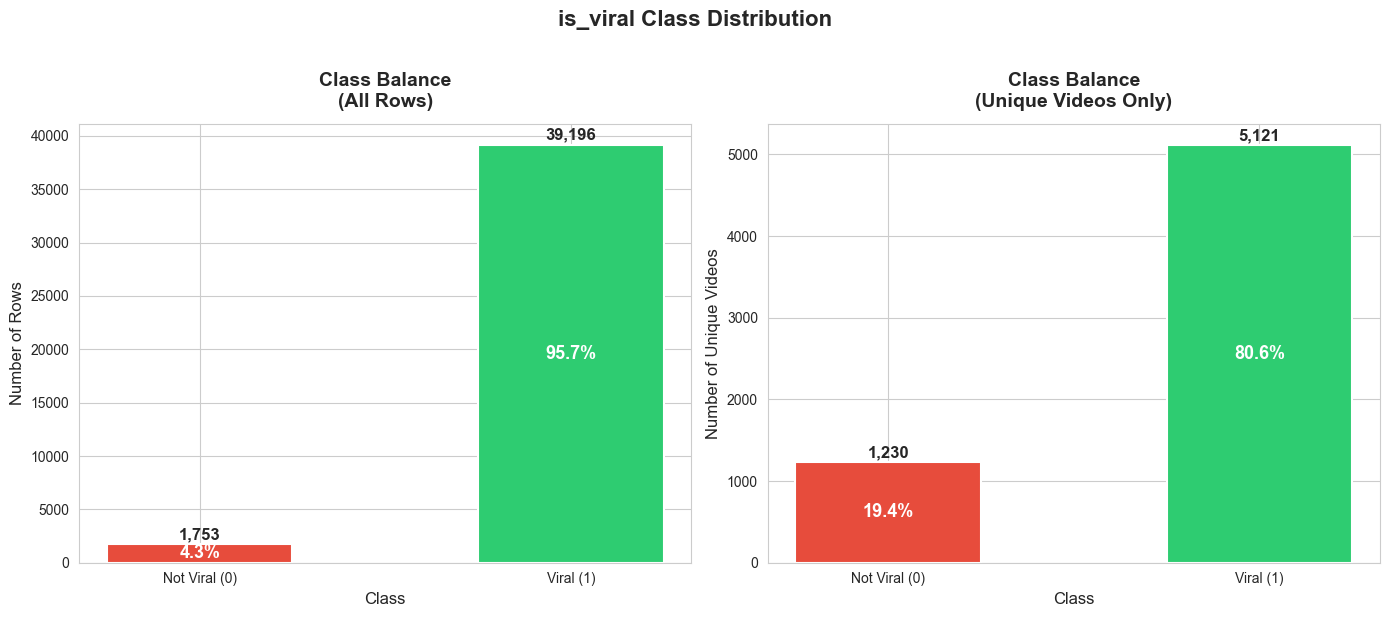

✅ Chart saved!


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# ── DRAW THE CLASS BALANCE BAR CHART ─────────────────────────────────────────

# set up the visual style
sns.set_style("whitegrid")

# create a figure with two side-by-side charts
# 1 row, 2 columns of charts — one for raw rows, one for unique videos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))


# ── LEFT CHART: all rows ──────────────────────────────────────────────────────

# labels for the x-axis
labels = ['Not Viral (0)', 'Viral (1)']

# the counts we already calculated
values = [counts.get(0, 0), counts.get(1, 0)]

# colors: red for non-viral, green for viral
colors = ['#e74c3c', '#2ecc71']

# draw the bars
bars1 = ax1.bar(labels, values, color=colors, width=0.5, edgecolor='white', linewidth=1.5)

# add the exact count number on top of each bar
for bar in bars1:
    ax1.text(
        bar.get_x() + bar.get_width() / 2,  # center of the bar horizontally
        bar.get_height() + 200,              # just above the top of the bar
        f"{int(bar.get_height()):,}",        # the count with comma formatting
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

# add percentage labels inside each bar
for bar, val in zip(bars1, values):
    pct = val / total * 100
    ax1.text(
        bar.get_x() + bar.get_width() / 2,  # center horizontally
        bar.get_height() / 2,               # middle of the bar vertically
        f"{pct:.1f}%",                      # percentage text
        ha='center', va='center', fontsize=13, color='white', fontweight='bold'
    )

ax1.set_title("Class Balance\n(All Rows)", fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Number of Rows", fontsize=12)
ax1.set_xlabel("Class", fontsize=12)


# ── RIGHT CHART: unique videos only ──────────────────────────────────────────

unique_values = [unique_counts.get(0, 0), unique_counts.get(1, 0)]
unique_total  = len(unique_videos)

bars2 = ax2.bar(labels, unique_values, color=colors, width=0.5, edgecolor='white', linewidth=1.5)

# count labels on top of bars
for bar in bars2:
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f"{int(bar.get_height()):,}",
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

# percentage labels inside bars
for bar, val in zip(bars2, unique_values):
    pct = val / unique_total * 100
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() / 2,
        f"{pct:.1f}%",
        ha='center', va='center', fontsize=13, color='white', fontweight='bold'
    )

ax2.set_title("Class Balance\n(Unique Videos Only)", fontsize=14, fontweight='bold', pad=12)
ax2.set_ylabel("Number of Unique Videos", fontsize=12)
ax2.set_xlabel("Class", fontsize=12)


# ── FINAL TOUCHES ─────────────────────────────────────────────────────────────

# add an overall title across both charts
fig.suptitle("is_viral Class Distribution", fontsize=16, fontweight='bold', y=1.02)

# tight_layout adjusts spacing so nothing overlaps
plt.tight_layout()

# save the chart to your charts folder
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"
os.makedirs(CHARTS_DIR, exist_ok=True)
plt.savefig(f"{CHARTS_DIR}/05_is_viral_class_balance.png", dpi=150, bbox_inches='tight')

plt.show()
print("✅ Chart saved!")

In [24]:
# save the updated dataframe with the new columns to your processed data folder
# so you don't have to recreate is_viral every time in future notebooks

PROCESSED_DIR = "/Users/suparna_deshmukh/projects/youtube-project/data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

save_path = f"{PROCESSED_DIR}/USvideos_with_target.csv"

# index=False means don't write the row numbers into the file
df.to_csv(save_path, index=False)

print(f"✅ Updated dataframe saved to:")
print(f"   {save_path}")
print(f"\nNew columns added to df:")
print(f"   trending_day_count — how many days each video trended")
print(f"   is_viral           — 1 if trended 3+ days, 0 otherwise")

✅ Updated dataframe saved to:
   /Users/suparna_deshmukh/projects/youtube-project/data/processed/USvideos_with_target.csv

New columns added to df:
   trending_day_count — how many days each video trended
   is_viral           — 1 if trended 3+ days, 0 otherwise


In [25]:
# re is Python's built-in library for working with text patterns
# it lets us find and remove special characters from text
import re

# numpy for numerical operations on arrays
import numpy as np

# pandas for dataframe manipulation
import pandas as pd

# TfidfVectorizer converts raw text into a matrix of numbers
# TF-IDF stands for Term Frequency–Inverse Document Frequency
# it gives higher scores to words that are important in one document
# but rare across all documents — making it great for finding meaningful words
from sklearn.feature_extraction.text import TfidfVectorizer

# scipy sparse matrices are memory-efficient ways to store mostly-zero matrices
# TF-IDF output is a sparse matrix — most words don't appear in most videos
from scipy.sparse import hstack, csr_matrix

print("✅ All libraries imported!")

✅ All libraries imported!


In [26]:
# skip this cell if df is already loaded in your session
# run it if you get NameError: df is not defined

data_path = "/Users/suparna_deshmukh/projects/youtube-project/data/processed/USvideos_with_target.csv"
df = pd.read_csv(data_path, encoding='latin-1')

print("✅ df loaded!")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

✅ df loaded!
Shape: (40949, 18)
Columns: ['video_id', 'trending_date', 'title', 'channel_title', 'category_id', 'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count', 'thumbnail_link', 'comments_disabled', 'ratings_disabled', 'video_error_or_removed', 'description', 'trending_day_count', 'is_viral']


In [27]:
# before cleaning, look at what the raw title and tags text actually looks like
# this helps us understand what characters need to be removed

print("── RAW TITLE EXAMPLES ────────────────────────")
# .head(5) shows the first 5 values
print(df['title'].head(5).to_string())

print("\n── RAW TAGS EXAMPLES ─────────────────────────")
print(df['tags'].head(5).to_string())

# check for any missing values in these columns
print("\n── NULL COUNTS ───────────────────────────────")
print(f"  title nulls : {df['title'].isnull().sum()}")
print(f"  tags nulls  : {df['tags'].isnull().sum()}")

── RAW TITLE EXAMPLES ────────────────────────
0                   WE WANT TO TALK ABOUT OUR MARRIAGE
1    The Trump Presidency: Last Week Tonight with J...
2    Racist Superman | Rudy Mancuso, King Bach & Le...
3                     Nickelback Lyrics: Real or Fake?
4                             I Dare You: GOING BALD!?

── RAW TAGS EXAMPLES ─────────────────────────
0                                      SHANtell martin
1    last week tonight trump presidency|"last week ...
2    racist superman|"rudy"|"mancuso"|"king"|"bach"...
3    rhett and link|"gmm"|"good mythical morning"|"...
4    ryan|"higa"|"higatv"|"nigahiga"|"i dare you"|"...

── NULL COUNTS ───────────────────────────────
  title nulls : 0
  tags nulls  : 0


In [28]:
# ── TEXT CLEANING FUNCTION ────────────────────────────────────────────────────

def clean_text(text):
    """
    Takes a raw string of text and returns a cleaned version.
    This function will be applied to every row in the title and tags columns.
    """

    # if the value is not a string (e.g. NaN/missing), return an empty string
    # isinstance() checks what type a variable is
    if not isinstance(text, str):
        return ""

    # convert all text to lowercase
    # so 'Music' and 'music' are treated as the same word
    text = text.lower()

    # in the tags column, tags are separated by pipe characters like: "tag1|tag2|tag3"
    # replace the pipe | character with a space so tags become separate words
    text = text.replace("|", " ")

    # remove anything inside square brackets like [Official Video]
    # re.sub() finds a pattern and replaces it with something else
    # \[.*?\] is a pattern that matches [ followed by anything followed by ]
    text = re.sub(r'\[.*?\]', '', text)

    # remove all characters that are NOT letters or spaces
    # [^a-z ] means: delete anything that isn't a lowercase letter or space
    # this removes: punctuation, numbers, emojis, special symbols
    text = re.sub(r'[^a-z ]', '', text)

    # remove extra spaces — if cleaning left multiple spaces in a row, collapse them
    # \s+ matches one or more whitespace characters
    text = re.sub(r'\s+', ' ', text)

    # strip() removes any leading or trailing spaces from the string
    text = text.strip()

    return text


# ── APPLY THE CLEANING FUNCTION TO BOTH COLUMNS ───────────────────────────────

# .apply() runs our clean_text function on every single row of the column
df['title_clean'] = df['title'].apply(clean_text)
df['tags_clean']  = df['tags'].apply(clean_text)

print("✅ Text cleaned!")
print("\n── BEFORE AND AFTER COMPARISON ───────────────")

# show side by side comparison for the first 3 rows
for i in range(3):
    print(f"\nRow {i+1}:")
    print(f"  BEFORE title : {df['title'].iloc[i]}")
    print(f"  AFTER  title : {df['title_clean'].iloc[i]}")
    print(f"  BEFORE tags  : {str(df['tags'].iloc[i])[:80]}...")
    print(f"  AFTER  tags  : {df['tags_clean'].iloc[i][:80]}...")

✅ Text cleaned!

── BEFORE AND AFTER COMPARISON ───────────────

Row 1:
  BEFORE title : WE WANT TO TALK ABOUT OUR MARRIAGE
  AFTER  title : we want to talk about our marriage
  BEFORE tags  : SHANtell martin...
  AFTER  tags  : shantell martin...

Row 2:
  BEFORE title : The Trump Presidency: Last Week Tonight with John Oliver (HBO)
  AFTER  title : the trump presidency last week tonight with john oliver hbo
  BEFORE tags  : last week tonight trump presidency|"last week tonight donald trump"|"john oliver...
  AFTER  tags  : last week tonight trump presidency last week tonight donald trump john oliver tr...

Row 3:
  BEFORE title : Racist Superman | Rudy Mancuso, King Bach & Lele Pons
  AFTER  title : racist superman rudy mancuso king bach lele pons
  BEFORE tags  : racist superman|"rudy"|"mancuso"|"king"|"bach"|"racist"|"superman"|"love"|"rudy ...
  AFTER  tags  : racist superman rudy mancuso king bach racist superman love rudy mancuso poo bea...


In [29]:
# ── COMBINE TITLE AND TAGS INTO ONE TEXT FIELD ────────────────────────────────

# for TF-IDF, we want to treat the title and tags as one combined piece of text
# combining them gives the model more words to learn from per video

# we repeat the title twice so it gets slightly more weight than tags
# this is a simple trick: if a word appears in the title, it's more important
df['combined_text'] = (
    df['title_clean'] + " " +   # title once
    df['title_clean'] + " " +   # title again (double weight)
    df['tags_clean']            # tags once
)

# fill any remaining blank combined_text values with an empty string
# fillna() replaces NaN values with whatever you pass in
df['combined_text'] = df['combined_text'].fillna("")

print("✅ Combined text column created!")
print("\n── COMBINED TEXT SAMPLE ──────────────────────")
print(df['combined_text'].iloc[0][:200], "...")
print(f"\nTotal rows with non-empty text: {(df['combined_text'] != '').sum():,}")

✅ Combined text column created!

── COMBINED TEXT SAMPLE ──────────────────────
we want to talk about our marriage we want to talk about our marriage shantell martin ...

Total rows with non-empty text: 40,949


In [30]:
# ── TF-IDF VECTORIZATION ──────────────────────────────────────────────────────

# TfidfVectorizer turns text into numbers that a machine learning model can use
# each word becomes a column, each row becomes a video
# the number in each cell = how important that word is for that video

tfidf = TfidfVectorizer(

    # max_features=100 means: only keep the 100 most important words
    # this controls how many NLP columns we create
    max_features=100,

    # stop_words='english' removes common words like 'the', 'a', 'is', 'and'
    # these words appear everywhere and carry no useful meaning for our model
    stop_words='english',

    # ngram_range=(1, 2) means: include single words AND pairs of words
    # for example: "music video" as one feature, not just "music" and "video" separately
    ngram_range=(1, 2),

    # min_df=2 means: ignore words that appear in fewer than 2 videos
    # very rare words are usually not useful for prediction
    min_df=2,

    # max_df=0.95 means: ignore words that appear in more than 95% of videos
    # words that appear almost everywhere are not distinctive enough to be useful
    max_df=0.95,

    # sublinear_tf=True applies a log transformation to word frequencies
    # this prevents very common words from dominating just because they appear often
    sublinear_tf=True
)

# fit_transform() does two things at once:
# 1. fit: learns which 100 words are most important across all videos
# 2. transform: converts every video's text into a row of 100 numbers
# the result is a sparse matrix with shape (num_rows, 100)
tfidf_matrix = tfidf.fit_transform(df['combined_text'])

print("✅ TF-IDF vectorization complete!")
print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"  → {tfidf_matrix.shape[0]:,} rows (one per video entry)")
print(f"  → {tfidf_matrix.shape[1]} columns (one per word/phrase)")

print("\n── TOP 30 WORDS LEARNED BY TF-IDF ───────────")
# get_feature_names_out() returns the list of words TF-IDF selected
feature_names = tfidf.get_feature_names_out()
print(list(feature_names[:30]))

✅ TF-IDF vectorization complete!
TF-IDF matrix shape: (40949, 100)
  → 40,949 rows (one per video entry)
  → 100 columns (one per word/phrase)

── TOP 30 WORDS LEARNED BY TF-IDF ───────────
['american', 'animation', 'apple', 'audio', 'beauty', 'best', 'big', 'black', 'bowl', 'buzzfeed', 'cake', 'car', 'cat', 'celebrity', 'challenge', 'channel', 'christmas', 'comedy', 'cooking', 'day', 'disney', 'diy', 'dog', 'entertainment', 'face', 'family', 'fashion', 'film', 'food', 'ft']


In [31]:
# ── NUMERIC FEATURE ENGINEERING ───────────────────────────────────────────────

# these are hand-crafted features we calculate from existing columns
# they capture information that raw text cannot — numbers, ratios, lengths

# make a clean copy to work on so we don't accidentally modify the original df
features = pd.DataFrame()


# FEATURE 1: like-to-view ratio
# what fraction of viewers liked the video
# higher ratio = more engaged audience
# we use clip(lower=0) to remove any negative values (data errors)
# we add 1 to views to avoid dividing by zero
features['like_view_ratio'] = (
    df['likes'].clip(lower=0) /
    (df['views'].clip(lower=1))
)


# FEATURE 2: dislike-to-view ratio
# what fraction of viewers disliked the video
# can indicate controversial content
features['dislike_view_ratio'] = (
    df['dislikes'].clip(lower=0) /
    (df['views'].clip(lower=1))
)


# FEATURE 3: comment-to-view ratio
# what fraction of viewers left a comment
# high comment ratio = high discussion/controversy
features['comment_view_ratio'] = (
    df['comment_count'].clip(lower=0) /
    (df['views'].clip(lower=1))
)


# FEATURE 4: like-to-dislike ratio
# measures overall sentiment — high = mostly positive reception
# we add 1 to dislikes to avoid dividing by zero
features['like_dislike_ratio'] = (
    df['likes'].clip(lower=0) /
    (df['dislikes'].clip(lower=0) + 1)
)


# FEATURE 5: title length in characters
# longer titles might be more descriptive or keyword-rich
# len() counts the number of characters in a string
features['title_length'] = df['title_clean'].apply(len)


# FEATURE 6: title word count
# number of words in the cleaned title
# .split() breaks a string into a list of words by splitting on spaces
features['title_word_count'] = df['title_clean'].apply(lambda x: len(x.split()))


# FEATURE 7: tag count
# number of individual tags the creator added
# original tags are separated by | so we count those separators + 1
# if tags column is missing/NaN, default to 0
features['tag_count'] = df['tags'].apply(
    lambda x: len(str(x).split('|')) if isinstance(x, str) else 0
)


# FEATURE 8: log of views
# raw view counts vary from thousands to hundreds of millions
# log scale compresses this range so extreme values don't dominate
# np.log1p is the same as log(x + 1) — safe for zero values
features['log_views'] = np.log1p(df['views'].clip(lower=0))


# FEATURE 9: log of likes
features['log_likes'] = np.log1p(df['likes'].clip(lower=0))


# FEATURE 10: log of comment count
features['log_comments'] = np.log1p(df['comment_count'].clip(lower=0))


# FEATURE 11: category_id as a numeric feature
# the category number itself carries meaning (10=Music, 24=Entertainment etc.)
features['category_id'] = df['category_id'].fillna(0)


# replace any infinite values with 0
# infinity can appear when dividing by very small numbers
features = features.replace([np.inf, -np.inf], 0)

# replace any remaining NaN values with 0
features = features.fillna(0)

print("✅ Numeric features created!")
print(f"\nNumeric features shape: {features.shape}")
print("\n── FEATURE COLUMNS ───────────────────────────")
for col in features.columns:
    print(f"  {col}")

print("\n── SAMPLE VALUES (first 3 rows) ──────────────")
print(features.head(3).to_string())

✅ Numeric features created!

Numeric features shape: (40949, 11)

── FEATURE COLUMNS ───────────────────────────
  like_view_ratio
  dislike_view_ratio
  comment_view_ratio
  like_dislike_ratio
  title_length
  title_word_count
  tag_count
  log_views
  log_likes
  log_comments
  category_id

── SAMPLE VALUES (first 3 rows) ──────────────
   like_view_ratio  dislike_view_ratio  comment_view_ratio  like_dislike_ratio  title_length  title_word_count  tag_count  log_views  log_likes  log_comments  category_id
0         0.076869            0.003963            0.021318           19.388945            34                 7          1  13.525659  10.960027      9.677528           22
1         0.040179            0.002541            0.005252           15.810151            59                10          4  14.698775  11.484382      9.449672           24
2         0.045758            0.001673            0.002563           27.347004            48                 8         23  14.975981  11.891595   

In [32]:
# ── COMBINE ALL FEATURES INTO FINAL MATRIX X ─────────────────────────────────

# we now have two sets of features:
# 1. tfidf_matrix  — 100 text-based columns (sparse matrix)
# 2. features      — 11 numeric columns (regular dataframe)

# to combine them, both need to be in the same format (sparse matrix)
# csr_matrix() converts our numeric dataframe into a sparse matrix
numeric_sparse = csr_matrix(features.values)

# hstack() stacks matrices side by side (horizontally)
# this gives us one wide matrix with 100 + 11 = 111 total columns
X = hstack([tfidf_matrix, numeric_sparse])

# ── CREATE THE TARGET COLUMN y ────────────────────────────────────────────────

# y is what we want the model to predict
# is_viral = 1 if the video trended for 3+ days, 0 otherwise
y = df['is_viral'].values

# .values converts the pandas Series into a plain numpy array
# machine learning models prefer numpy arrays over pandas Series


print("✅ Final feature matrix X and target y created!")
print("\n── FINAL DIMENSIONS ──────────────────────────")
print(f"  X shape : {X.shape}")
print(f"    → {X.shape[0]:,} rows  (one per video entry)")
print(f"    → {X.shape[1]} columns (100 TF-IDF + 11 numeric)")
print(f"\n  y shape : {y.shape}")
print(f"    → {y.shape[0]:,} values (0 = not viral, 1 = viral)")

print("\n── CLASS DISTRIBUTION IN y ───────────────────")
unique, counts = np.unique(y, return_counts=True)
for label, count in zip(unique, counts):
    name = "Viral (1)    " if label == 1 else "Not Viral (0)"
    pct = count / len(y) * 100
    print(f"  {name} : {count:>7,}  ({pct:.1f}%)")

✅ Final feature matrix X and target y created!

── FINAL DIMENSIONS ──────────────────────────
  X shape : (40949, 111)
    → 40,949 rows  (one per video entry)
    → 111 columns (100 TF-IDF + 11 numeric)

  y shape : (40949,)
    → 40,949 values (0 = not viral, 1 = viral)

── CLASS DISTRIBUTION IN y ───────────────────
  Not Viral (0) :   1,753  (4.3%)
  Viral (1)     :  39,196  (95.7%)


In [33]:
# ── SAVE A READABLE LIST OF ALL FEATURE NAMES ────────────────────────────────

# store all feature names in one list so we can reference them later
# this is useful when interpreting model results and SHAP plots

# get the 100 TF-IDF feature names
tfidf_feature_names = list(tfidf.get_feature_names_out())

# get the 11 numeric feature names
numeric_feature_names = list(features.columns)

# combine both lists into one master list
all_feature_names = tfidf_feature_names + numeric_feature_names

print(f"Total features: {len(all_feature_names)}")
print(f"  TF-IDF features  : {len(tfidf_feature_names)}")
print(f"  Numeric features : {len(numeric_feature_names)}")

print("\n── ALL FEATURE NAMES ─────────────────────────")
for i, name in enumerate(all_feature_names):
    print(f"  {i+1:>3}. {name}")

Total features: 111
  TF-IDF features  : 100
  Numeric features : 11

── ALL FEATURE NAMES ─────────────────────────
    1. american
    2. animation
    3. apple
    4. audio
    5. beauty
    6. best
    7. big
    8. black
    9. bowl
   10. buzzfeed
   11. cake
   12. car
   13. cat
   14. celebrity
   15. challenge
   16. channel
   17. christmas
   18. comedy
   19. cooking
   20. day
   21. disney
   22. diy
   23. dog
   24. entertainment
   25. face
   26. family
   27. fashion
   28. film
   29. food
   30. ft
   31. funny
   32. game
   33. hair
   34. highlights
   35. home
   36. house
   37. interview
   38. iphone
   39. james
   40. john
   41. kids
   42. late
   43. life
   44. live
   45. love
   46. make
   47. makeup
   48. makeup tutorial
   49. man
   50. movie
   51. movies
   52. music
   53. music video
   54. nba
   55. nbc
   56. new
   57. news
   58. night
   59. official
   60. official trailer
   61. official video
   62. people
   63. perfect
   64. pop

In [34]:
# StandardScaler transforms numeric columns so they all have
# mean = 0 and standard deviation = 1
# this is essential before clustering — without scaling, 'views' (millions)
# would completely overpower 'like_ratio' (tiny decimals)
from sklearn.preprocessing import StandardScaler

# KMeans is the clustering algorithm
# it groups rows into k clusters by finding the most similar videos together
from sklearn.cluster import KMeans

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# numpy for numerical operations
import numpy as np

# pandas for dataframe work
import pandas as pd

# os for folder creation
import os

# set chart style
sns.set_style("whitegrid")

# define charts folder
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"
os.makedirs(CHARTS_DIR, exist_ok=True)

print("✅ Libraries imported!")

✅ Libraries imported!


In [35]:
# skip this cell if df is already in your session
# run it only if you get NameError: df is not defined

data_path = "/Users/suparna_deshmukh/projects/youtube-project/data/processed/USvideos_with_target.csv"
df = pd.read_csv(data_path, encoding='latin-1')

print("✅ df reloaded!")
print(f"Shape: {df.shape}")

✅ df reloaded!
Shape: (40949, 18)


In [36]:
# ── SELECT ONLY THE NUMERIC COLUMNS FOR CLUSTERING ───────────────────────────

# clustering works on numbers only — we pick the most meaningful ones
# views        : raw popularity signal
# likes        : positive engagement signal
# comment_count: discussion/controversy signal
# like_ratio   : quality of engagement (likes relative to how many watched)

# first rebuild like_ratio if it doesn't exist yet in df
# we add 1 to views to avoid dividing by zero
df['like_ratio'] = df['likes'].clip(lower=0) / (df['views'].clip(lower=1))

# select the four columns we want to cluster on
# .copy() makes a fresh copy so we don't accidentally modify df
cluster_df = df[['views', 'likes', 'comment_count', 'like_ratio']].copy()

# replace any infinite or NaN values with 0
# these can appear from division operations and will crash the scaler
cluster_df = cluster_df.replace([float('inf'), float('-inf')], 0)
cluster_df = cluster_df.fillna(0)

print("✅ Numeric columns selected!")
print(f"\nShape: {cluster_df.shape}")
print("\n── BASIC STATISTICS ──────────────────────────")
print(cluster_df.describe().round(2).to_string())

✅ Numeric columns selected!

Shape: (40949, 4)

── BASIC STATISTICS ──────────────────────────
              views       likes  comment_count  like_ratio
count  4.094900e+04    40949.00       40949.00    40949.00
mean   2.360785e+06    74266.70        8446.80        0.03
std    7.394114e+06   228885.34       37430.49        0.03
min    5.490000e+02        0.00           0.00        0.00
25%    2.423290e+05     5424.00         614.00        0.01
50%    6.818610e+05    18091.00        1856.00        0.03
75%    1.823157e+06    55417.00        5755.00        0.05
max    2.252119e+08  5613827.00     1361580.00        0.29


In [37]:
# ── STANDARDIZE THE FEATURES WITH STANDARDSCALER ─────────────────────────────

# without scaling, KMeans measures distance between points using raw values
# 'views' ranges from 0 to 200,000,000 — 'like_ratio' ranges from 0 to 1
# the algorithm would almost entirely ignore like_ratio because views is so huge
# StandardScaler fixes this by putting all columns on the same scale

# create the scaler object
scaler = StandardScaler()

# fit_transform() does two things:
# 1. fit: calculates the mean and std of each column
# 2. transform: subtracts the mean and divides by std for every value
# result is a numpy array where each column now has mean≈0, std≈1
X_scaled = scaler.fit_transform(cluster_df)

print("✅ Features scaled!")
print(f"\nScaled matrix shape: {X_scaled.shape}")

print("\n── BEFORE SCALING (first row raw values) ─────")
print(cluster_df.iloc[0].to_string())

print("\n── AFTER SCALING (first row scaled values) ───")
for col, val in zip(cluster_df.columns, X_scaled[0]):
    print(f"  {col:<20} : {val:.4f}")

✅ Features scaled!

Scaled matrix shape: (40949, 4)

── BEFORE SCALING (first row raw values) ─────
views            748374.000000
likes             57527.000000
comment_count     15954.000000
like_ratio            0.076869

── AFTER SCALING (first row scaled values) ───
  views                : -0.2181
  likes                : -0.0731
  comment_count        : 0.2006
  like_ratio           : 1.5720


In [38]:
# ── ELBOW METHOD ──────────────────────────────────────────────────────────────

# KMeans needs us to tell it HOW MANY clusters to find (the k value)
# the elbow method helps us choose k by testing multiple values
# for each k, we measure inertia = total distance of all points from their cluster center
# lower inertia = tighter, more compact clusters
# but more clusters always = lower inertia, so we look for the "elbow":
# the point where adding more clusters stops giving big improvements

# we will test k values from 2 to 10
k_values = range(2, 11)

# empty list to store inertia for each k
inertia_values = []

print("Testing k values — this may take a moment...")
print("━" * 40)

for k in k_values:

    # create a KMeans model with k clusters
    # n_init=10 means: run KMeans 10 times with different starting points
    #   and keep the best result — avoids getting stuck in a bad solution
    # random_state=42 makes results reproducible — same result every time you run
    # max_iter=300 is the maximum number of steps before stopping
    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42,
        max_iter=300
    )

    # fit() runs the KMeans algorithm on our scaled data
    kmeans.fit(X_scaled)

    # .inertia_ is the total distance of all points from their assigned cluster center
    # lower = more compact clusters
    inertia_values.append(kmeans.inertia_)

    print(f"  k={k}  →  inertia: {kmeans.inertia_:,.1f}")

print("━" * 40)
print("✅ Elbow method complete!")

Testing k values — this may take a moment...
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  k=2  →  inertia: 105,933.5
  k=3  →  inertia: 80,151.3
  k=4  →  inertia: 56,792.2
  k=5  →  inertia: 47,102.2
  k=6  →  inertia: 39,887.5
  k=7  →  inertia: 34,922.1
  k=8  →  inertia: 30,427.7
  k=9  →  inertia: 27,435.7
  k=10  →  inertia: 24,569.0
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
✅ Elbow method complete!


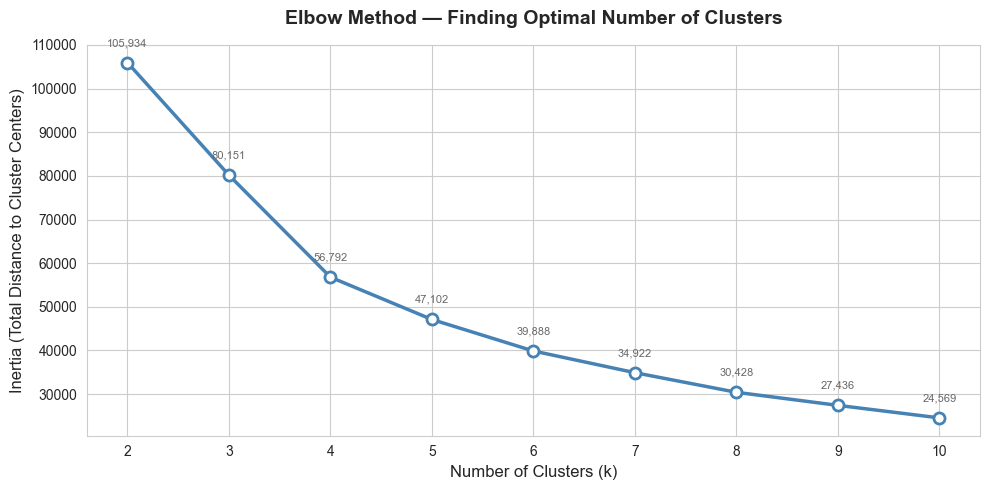

✅ Elbow chart saved!

Look at the chart — find the k where the line bends like an elbow.
The bend = the point where adding more clusters stops helping much.
Tell me what k you think looks best and we will use that value next.


In [39]:
# ── PLOT THE ELBOW CHART ──────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))

# plot the inertia values as a line with circle markers at each k
ax.plot(
    list(k_values),       # x-axis: k values 2 through 10
    inertia_values,       # y-axis: inertia for each k
    marker='o',           # draw a circle at each point
    linewidth=2.5,
    markersize=8,
    color='steelblue',
    markerfacecolor='white',
    markeredgewidth=2
)

# add the inertia number next to each point so it's easy to read
for k, inertia in zip(k_values, inertia_values):
    ax.annotate(
        f"{inertia:,.0f}",          # the text to show
        (k, inertia),               # the point to annotate
        textcoords="offset points", # position relative to the point
        xytext=(0, 12),             # 12 points above the dot
        ha='center',
        fontsize=8,
        color='dimgray'
    )

ax.set_title("Elbow Method — Finding Optimal Number of Clusters",
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Number of Clusters (k)", fontsize=12)
ax.set_ylabel("Inertia (Total Distance to Cluster Centers)", fontsize=12)

# mark each k value explicitly on x-axis so it's clear
ax.set_xticks(list(k_values))

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/06_elbow_chart.png", dpi=150)
plt.show()

print("✅ Elbow chart saved!")
print("\nLook at the chart — find the k where the line bends like an elbow.")
print("The bend = the point where adding more clusters stops helping much.")
print("Tell me what k you think looks best and we will use that value next.")

In [40]:
# ── FIT FINAL KMEANS MODEL ────────────────────────────────────────────────────

# SET THIS to whatever k looked best in your elbow chart
# common choices are 3, 4, or 5 — change the number below based on what you see
BEST_K = 4

# create the final KMeans model with the chosen number of clusters
final_kmeans = KMeans(
    n_clusters=BEST_K,
    n_init=10,
    random_state=42,
    max_iter=300
)

# fit_predict() runs KMeans AND returns the cluster label for every row
# each label is a number: 0, 1, 2, or 3 (if k=4)
cluster_labels = final_kmeans.fit_predict(X_scaled)

# add the cluster label back to the original dataframe as a new column
# now every video row knows which cluster it belongs to
df['cluster'] = cluster_labels

print(f"✅ KMeans fitted with k={BEST_K}!")
print(f"\nCluster label counts:")
print(df['cluster'].value_counts().sort_index().to_string())

✅ KMeans fitted with k=4!

Cluster label counts:
cluster
0    10778
1       74
2    29289
3      808


In [41]:
# ── ANALYZE EACH CLUSTER AND ASSIGN HUMAN-READABLE NAMES ─────────────────────

# calculate the average views, likes, comments, and like_ratio per cluster
# groupby('cluster') groups all rows by their cluster number
# then we calculate the mean of each column within each group
cluster_summary = df.groupby('cluster').agg(
    video_count   = ('views',         'count'),   # how many videos in this cluster
    avg_views     = ('views',         'mean'),     # average view count
    avg_likes     = ('likes',         'mean'),     # average like count
    avg_comments  = ('comment_count', 'mean'),     # average comment count
    avg_like_ratio= ('like_ratio',    'mean'),     # average like-to-view ratio
    viral_rate    = ('is_viral',      'mean')      # fraction that are viral (0 to 1)
).reset_index()

# sort clusters from lowest to highest average views
# this makes it easier to assign names from "least popular" to "most popular"
cluster_summary = cluster_summary.sort_values('avg_views').reset_index(drop=True)

# ── ASSIGN HUMAN-READABLE NAMES ───────────────────────────────────────────────

# we assign names based on rank order of average views
# adjust these names if your clusters look different after inspecting the numbers
cluster_name_map = {
    0: "🌱 Niche Content",       # lowest views — small but engaged audiences
    1: "📈 Rising Creators",     # moderate views — growing channels
    2: "🔥 Mainstream Hits",     # high views — popular trending content
    3: "🚀 Viral Giants"         # highest views — mega viral videos
}

# add the name column using the rank position (0=lowest, 3=highest views)
# we map by position in the sorted summary, not by raw cluster number
cluster_summary['cluster_name'] = [
    cluster_name_map[i] for i in range(len(cluster_summary))
]

# also map the names back to df using the original cluster numbers
# so each row in df gets a readable name
rank_to_name = {
    row['cluster']: cluster_name_map[i]
    for i, row in cluster_summary.iterrows()
}
df['cluster_name'] = df['cluster'].map(rank_to_name)

print("✅ Cluster names assigned!")

✅ Cluster names assigned!


In [42]:
# ── PRINT READABLE CLUSTER SUMMARY ───────────────────────────────────────────

print("━" * 75)
print("  CLUSTER SUMMARY — YouTube Trending Videos")
print("━" * 75)

# loop through each cluster row and print a formatted block
for _, row in cluster_summary.iterrows():
    print(f"\n  {row['cluster_name']}")
    print(f"  {'─'*45}")
    print(f"  Videos in cluster   : {int(row['video_count']):>10,}")
    print(f"  Avg views           : {int(row['avg_views']):>10,}")
    print(f"  Avg likes           : {int(row['avg_likes']):>10,}")
    print(f"  Avg comments        : {int(row['avg_comments']):>10,}")
    print(f"  Avg like ratio      : {row['avg_like_ratio']:>10.4f}")
    print(f"  Viral rate          : {row['viral_rate']*100:>9.1f}%")

print("\n" + "━" * 75)

# also save the summary as a CSV
REPORTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/reports"
os.makedirs(REPORTS_DIR, exist_ok=True)
cluster_summary.to_csv(f"{REPORTS_DIR}/cluster_summary.csv", index=False)
print("✅ Cluster summary saved to outputs/reports/cluster_summary.csv")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLUSTER SUMMARY — YouTube Trending Videos
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  🌱 Niche Content
  ─────────────────────────────────────────────
  Videos in cluster   :     10,778
  Avg views           :  1,451,017
  Avg likes           :     90,841
  Avg comments        :      9,706
  Avg like ratio      :     0.0686
  Viral rate          :      97.4%

  📈 Rising Creators
  ─────────────────────────────────────────────
  Videos in cluster   :     29,289
  Avg views           :  1,654,558
  Avg likes           :     34,377
  Avg comments        :      3,862
  Avg like ratio      :     0.0215
  Viral rate          :      95.0%

  🔥 Mainstream Hits
  ─────────────────────────────────────────────
  Videos in cluster   :        808
  Avg views           : 31,227,016
  Avg likes           :    996,125
  Avg comments        :     97,570
  Avg like ratio      :     0.0454
  Vi

/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/4199931693.py:47: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/4199931693.py:47: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/4199931693.py:47: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/4199931693.py:47: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/4199931693.py:48: UserWarning: Glyph 127793 (\N{SEEDLING}) missing from font(s) Arial.
  plt.savefig(f"{CHARTS_DIR}/07_cluster_profiles.png", dpi=150, bbox_inches='tight')
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58

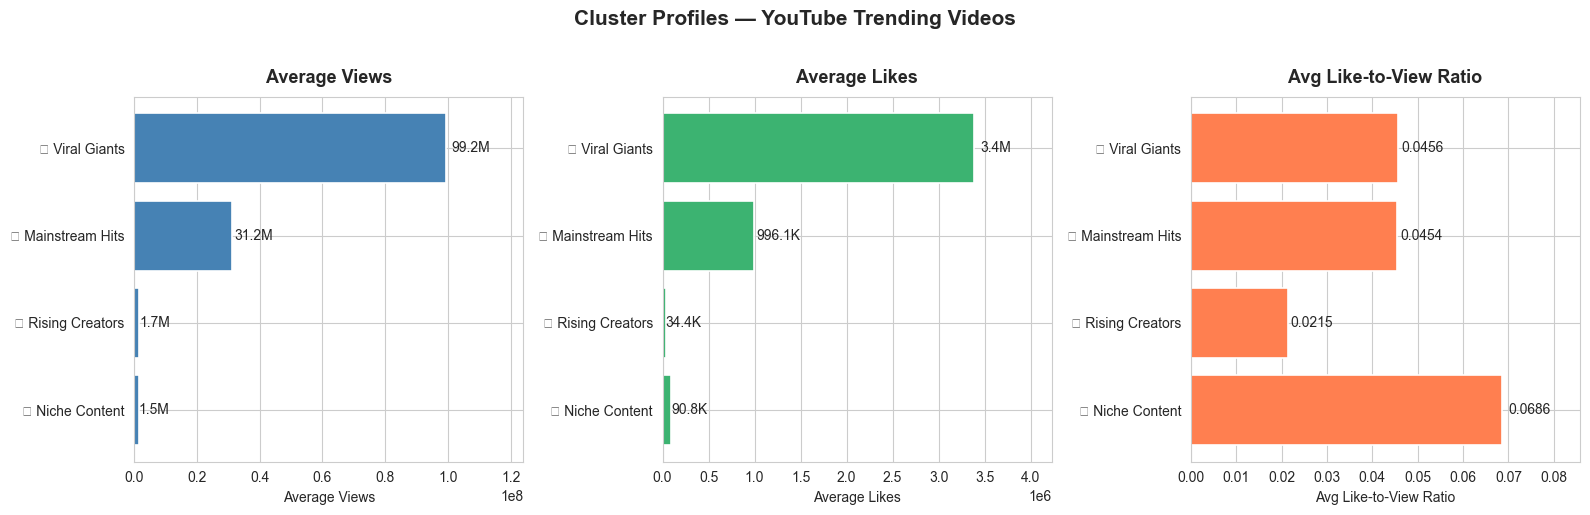

✅ Cluster profile chart saved!


In [43]:
# ── BAR CHART COMPARING CLUSTERS BY AVERAGE VIEWS ────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# list of metrics to plot — one bar chart per metric
metrics = [
    ('avg_views',      'Average Views',       'steelblue'),
    ('avg_likes',      'Average Likes',       'mediumseagreen'),
    ('avg_like_ratio', 'Avg Like-to-View Ratio', 'coral')
]

for ax, (metric, title, color) in zip(axes, metrics):

    # draw horizontal bar chart — easier to read long cluster names
    bars = ax.barh(
        cluster_summary['cluster_name'],  # y-axis: cluster names
        cluster_summary[metric],          # x-axis: the metric value
        color=color,
        edgecolor='white',
        linewidth=1.2
    )

    # add value labels at the end of each bar
    for bar in bars:
        width = bar.get_width()
        # format large numbers with K/M suffix for readability
        if width >= 1_000_000:
            label = f"{width/1_000_000:.1f}M"
        elif width >= 1_000:
            label = f"{width/1_000:.1f}K"
        else:
            label = f"{width:.4f}"

        ax.text(
            width * 1.02,                         # just right of the bar end
            bar.get_y() + bar.get_height() / 2,   # vertically centered
            label,
            va='center', ha='left', fontsize=10
        )

    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel(title, fontsize=10)
    ax.set_xlim(0, cluster_summary[metric].max() * 1.25)

plt.suptitle("Cluster Profiles — YouTube Trending Videos",
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/07_cluster_profiles.png", dpi=150, bbox_inches='tight')
plt.show()

print("✅ Cluster profile chart saved!")

In [44]:
# ── ASSIGN HUMAN-READABLE NAMES TO CLUSTERS ───────────────────────────────────

# first rebuild the cluster_summary with correct sort order
# we sort by avg_views so cluster names go from lowest to highest views
cluster_summary = df.groupby('cluster').agg(
    video_count    = ('views',         'count'),
    avg_views      = ('views',         'mean'),
    avg_likes      = ('likes',         'mean'),
    avg_comments   = ('comment_count', 'mean'),
    avg_like_ratio = ('like_ratio',    'mean'),
    viral_rate     = ('is_viral',      'mean')
).reset_index()

# sort from lowest to highest avg_views so rank 0 = least popular
cluster_summary = cluster_summary.sort_values('avg_views').reset_index(drop=True)

# updated names based on actual numbers from your output:
# rank 0 — 1.4M avg views, highest like ratio (0.068) — loyal engaged audience
# rank 1 — 1.6M avg views, largest group (29k videos) — typical trending video
# rank 2 — 31M avg views, 808 videos — genuinely viral mainstream content
# rank 3 — 99M avg views, only 74 videos — mega viral once-in-a-generation videos
cluster_name_map = {
    0: "💜 Engaged Community",
    1: "📺 Standard Trending",
    2: "🔥 Mainstream Hits",
    3: "🚀 Viral Giants"
}

# add cluster_name column to cluster_summary using rank position
cluster_summary['cluster_name'] = [
    cluster_name_map[i] for i in range(len(cluster_summary))
]

# build a mapping from raw cluster number → name
# this maps the original KMeans cluster numbers (0,1,2,3) to readable names
rank_to_name = {
    row['cluster']: cluster_name_map[i]
    for i, row in cluster_summary.iterrows()
}

# overwrite the cluster_name column in df with updated names
df['cluster_name'] = df['cluster'].map(rank_to_name)

print("✅ Cluster names updated!")
print("\nCluster → Name mapping:")
for cluster_num, name in rank_to_name.items():
    print(f"  Cluster {cluster_num} → {name}")

✅ Cluster names updated!

Cluster → Name mapping:
  Cluster 0 → 💜 Engaged Community
  Cluster 2 → 📺 Standard Trending
  Cluster 3 → 🔥 Mainstream Hits
  Cluster 1 → 🚀 Viral Giants


In [45]:
# ── PRINT UPDATED CLUSTER SUMMARY ─────────────────────────────────────────────

print("━" * 75)
print("  CLUSTER SUMMARY — YouTube Trending Videos (Updated Names)")
print("━" * 75)

# loop through each cluster row and print a clean formatted block
for _, row in cluster_summary.iterrows():
    print(f"\n  {row['cluster_name']}")
    print(f"  {'─' * 45}")
    print(f"  Videos in cluster   : {int(row['video_count']):>10,}")
    print(f"  Avg views           : {int(row['avg_views']):>10,}")
    print(f"  Avg likes           : {int(row['avg_likes']):>10,}")
    print(f"  Avg comments        : {int(row['avg_comments']):>10,}")
    print(f"  Avg like ratio      : {row['avg_like_ratio']:>10.4f}")
    print(f"  Viral rate          : {row['viral_rate']*100:>9.1f}%")

print("\n" + "━" * 75)

# note about class imbalance for classification stage
print("\n⚠️  NOTE ON CLASS SIZES:")
print(f"  Largest cluster  : 📺 Standard Trending  — {29289:>6,} videos")
print(f"  Smallest cluster : 🚀 Viral Giants       — {74:>6,} videos")
print(f"  Size ratio       : {29289//74}:1 — we will handle this in classification")

# overwrite the old CSV with updated names
REPORTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/reports"
os.makedirs(REPORTS_DIR, exist_ok=True)
cluster_summary.to_csv(f"{REPORTS_DIR}/cluster_summary.csv", index=False)
print("\n✅ Updated cluster summary saved to outputs/reports/cluster_summary.csv")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLUSTER SUMMARY — YouTube Trending Videos (Updated Names)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  💜 Engaged Community
  ─────────────────────────────────────────────
  Videos in cluster   :     10,778
  Avg views           :  1,451,017
  Avg likes           :     90,841
  Avg comments        :      9,706
  Avg like ratio      :     0.0686
  Viral rate          :      97.4%

  📺 Standard Trending
  ─────────────────────────────────────────────
  Videos in cluster   :     29,289
  Avg views           :  1,654,558
  Avg likes           :     34,377
  Avg comments        :      3,862
  Avg like ratio      :     0.0215
  Viral rate          :      95.0%

  🔥 Mainstream Hits
  ─────────────────────────────────────────────
  Videos in cluster   :        808
  Avg views           : 31,227,016
  Avg likes           :    996,125
  Avg comments        :     97,570
  Avg like ratio 

/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:69: UserWarning: Glyph 128156 (\N{PURPLE HEART}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:69: UserWarning: Glyph 128250 (\N{TELEVISION}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:69: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:69: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:73: UserWarning: Glyph 128156 (\N{PURPLE HEART}) missing from font(s) Arial.
  plt.savefig(save_path, dpi=150, bbox_inches='tight')
/var/folders/8r/56mbx9cd03lcl4qwt2y0j5mw0000gn/T/ipykernel_58022/3417770774.py:73: UserWarning: G

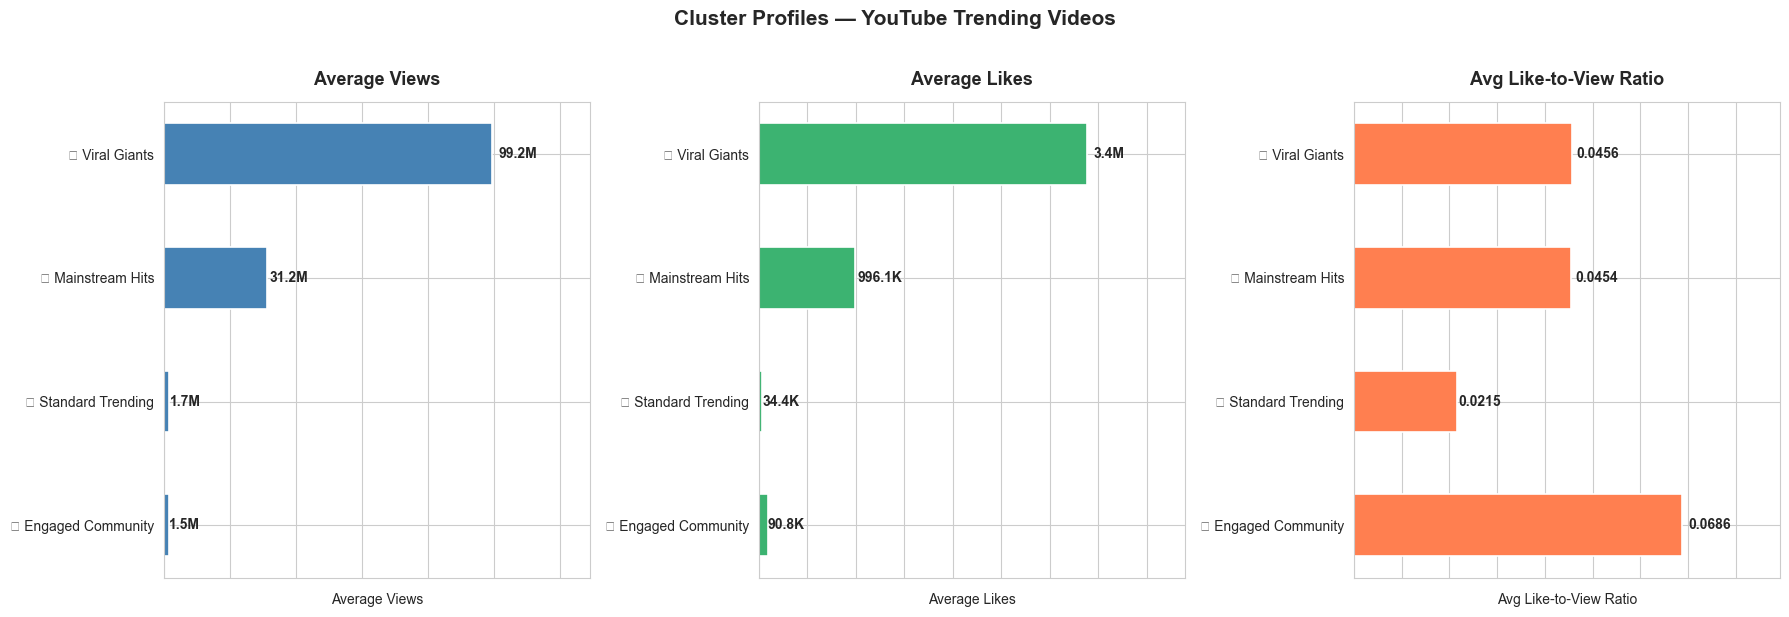

✅ Updated cluster profile chart saved to:
   /Users/suparna_deshmukh/projects/youtube-project/charts/07_cluster_profiles.png


In [46]:
# ── PLOT UPDATED CLUSTER COMPARISON CHARTS ────────────────────────────────────

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os

sns.set_style("whitegrid")
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"
os.makedirs(CHARTS_DIR, exist_ok=True)

# create a figure with 1 row and 3 side-by-side charts
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# define the three metrics we want to compare visually
metrics = [
    ('avg_views',      'Average Views',           'steelblue'),
    ('avg_likes',      'Average Likes',            'mediumseagreen'),
    ('avg_like_ratio', 'Avg Like-to-View Ratio',   'coral')
]

for ax, (metric, title, color) in zip(axes, metrics):

    # draw horizontal bars — easier to read long cluster names
    bars = ax.barh(
        cluster_summary['cluster_name'],   # y-axis: cluster names
        cluster_summary[metric],           # x-axis: the metric value
        color=color,
        edgecolor='white',
        linewidth=1.2,
        height=0.5
    )

    # add a value label at the end of each bar
    for bar in bars:
        width = bar.get_width()

        # format numbers smartly: M for millions, K for thousands
        if width >= 1_000_000:
            label = f"{width / 1_000_000:.1f}M"
        elif width >= 1_000:
            label = f"{width / 1_000:.1f}K"
        else:
            # for small decimals like like_ratio, show 4 decimal places
            label = f"{width:.4f}"

        ax.text(
            width * 1.02,                          # just right of the bar tip
            bar.get_y() + bar.get_height() / 2,    # vertically centered on bar
            label,
            va='center', ha='left', fontsize=10, fontweight='bold'
        )

    ax.set_title(title, fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel(title, fontsize=10)

    # give extra horizontal room so labels don't get clipped
    ax.set_xlim(0, cluster_summary[metric].max() * 1.3)

    # remove the x-axis tick numbers — the bar labels are cleaner
    ax.xaxis.set_major_formatter(mticker.NullFormatter())

# overall title across all three charts
fig.suptitle(
    "Cluster Profiles — YouTube Trending Videos",
    fontsize=15, fontweight='bold', y=1.02
)

plt.tight_layout()

# save and overwrite the old chart file
save_path = f"{CHARTS_DIR}/07_cluster_profiles.png"
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Updated cluster profile chart saved to:")
print(f"   {save_path}")

In [47]:
# train_test_split divides our data into training and testing sets
# we train the model on 80% of data and test it on the remaining 20%
from sklearn.model_selection import train_test_split

# XGBClassifier is the XGBoost model — one of the best performing
# classifiers for tabular data like ours
from xgboost import XGBClassifier

# classification_report prints precision, recall, and F1 score per class
# confusion_matrix shows how many predictions were correct vs wrong
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# numpy for array operations
import numpy as np

# joblib saves and loads trained models to disk as .pkl files
import joblib

# os for folder creation
import os

sns.set_style("whitegrid")

# define the folder where the trained model will be saved
MODELS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/models"
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CHARTS_DIR, exist_ok=True)

print("✅ Libraries imported!")

ModuleNotFoundError: No module named 'xgboost'

In [48]:
import xgboost
print("✅ XGBoost version:", xgboost.__version__)

ModuleNotFoundError: No module named 'xgboost'

In [49]:
import sys
print(sys.executable)

/Library/Frameworks/Python.framework/Versions/3.14/bin/python3.14


In [50]:
# train_test_split divides our data into training and testing sets
# we train the model on 80% of data and test it on the remaining 20%
from sklearn.model_selection import train_test_split

# XGBClassifier is the XGBoost model — one of the best performing
# classifiers for tabular data like ours
from xgboost import XGBClassifier

# classification_report prints precision, recall, and F1 score per class
# confusion_matrix shows how many predictions were correct vs wrong
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# numpy for array operations
import numpy as np

# joblib saves and loads trained models to disk as .pkl files
import joblib

# os for folder creation
import os

sns.set_style("whitegrid")

# define the folder where the trained model will be saved
MODELS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/models"
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CHARTS_DIR, exist_ok=True)

print("✅ Libraries imported!")

XGBoostError: 
XGBoost Library (libxgboost.dylib) could not be loaded.
Likely causes:
  * OpenMP runtime is not installed
    - vcomp140.dll or libgomp-1.dll for Windows
    - libomp.dylib for Mac OSX
    - libgomp.so for Linux and other UNIX-like OSes
    Mac OSX users: Run `brew install libomp` to install OpenMP runtime.

  * You are running 32-bit Python on a 64-bit OS

Error message(s): ["dlopen(/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib\n  Referenced from: <1A0D8152-BF46-3BE0-B651-EE965C187777> /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/xgboost/lib/libxgboost.dylib\n  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/O

In [51]:
# train_test_split divides our data into training and testing sets
# we train the model on 80% of data and test it on the remaining 20%
from sklearn.model_selection import train_test_split

# XGBClassifier is the XGBoost model — one of the best performing
# classifiers for tabular data like ours
from xgboost import XGBClassifier

# classification_report prints precision, recall, and F1 score per class
# confusion_matrix shows how many predictions were correct vs wrong
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# numpy for array operations
import numpy as np

# joblib saves and loads trained models to disk as .pkl files
import joblib

# os for folder creation
import os

sns.set_style("whitegrid")

# define the folder where the trained model will be saved
MODELS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/models"
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CHARTS_DIR, exist_ok=True)

print("✅ Libraries imported!")

✅ Libraries imported!


In [52]:
# ── CONFIRM X AND y EXIST AND HAVE THE RIGHT SHAPES ──────────────────────────

# X is our feature matrix — 111 columns (100 TF-IDF + 11 numeric)
# y is our target array — 0 = not viral, 1 = viral
# both were created in the NLP feature engineering notebook section

print("── CHECKING X AND y ──────────────────────────")
print(f"  X shape : {X.shape}")
print(f"  y shape : {y.shape}")

# count class distribution in y
unique, counts = np.unique(y, return_counts=True)
print("\n── CLASS DISTRIBUTION IN y ───────────────────")
for label, count in zip(unique, counts):
    name = "Viral (1)    " if label == 1 else "Not Viral (0)"
    pct  = count / len(y) * 100
    print(f"  {name} : {count:>7,}  ({pct:.1f}%)")

── CHECKING X AND y ──────────────────────────
  X shape : (40949, 111)
  y shape : (40949,)

── CLASS DISTRIBUTION IN y ───────────────────
  Not Viral (0) :   1,753  (4.3%)
  Viral (1)     :  39,196  (95.7%)


In [53]:
# ── SPLIT DATA INTO 80% TRAIN AND 20% TEST ────────────────────────────────────

# train_test_split randomly divides X and y into four pieces:
# X_train — the features the model will learn from
# X_test  — the features we will use to test the model later
# y_train — the correct answers for training rows
# y_test  — the correct answers for test rows (we hide these from the model)

X_train, X_test, y_train, y_test = train_test_split(

    X,              # our full feature matrix
    y,              # our full target array

    # test_size=0.2 means 20% of rows go to test, 80% go to train
    test_size=0.2,

    # random_state=42 makes the split reproducible
    # every time you run this cell you get the exact same split
    random_state=42,

    # stratify=y ensures both train and test sets have the same
    # proportion of viral vs not-viral videos as the full dataset
    # without this, by chance one set might have very few viral videos
    stratify=y
)

print("✅ Data split complete!")
print(f"\n  Training set   : {X_train.shape[0]:,} rows  ({X_train.shape[0]/len(y)*100:.0f}%)")
print(f"  Test set       : {X_test.shape[0]:,} rows  ({X_test.shape[0]/len(y)*100:.0f}%)")

# confirm class balance is preserved in both sets
print("\n── CLASS BALANCE IN TRAINING SET ─────────────")
unique, counts = np.unique(y_train, return_counts=True)
for label, count in zip(unique, counts):
    name = "Viral (1)    " if label == 1 else "Not Viral (0)"
    print(f"  {name} : {count:>6,}  ({count/len(y_train)*100:.1f}%)")

print("\n── CLASS BALANCE IN TEST SET ─────────────────")
unique, counts = np.unique(y_test, return_counts=True)
for label, count in zip(unique, counts):
    name = "Viral (1)    " if label == 1 else "Not Viral (0)"
    print(f"  {name} : {count:>6,}  ({count/len(y_test)*100:.1f}%)")

✅ Data split complete!

  Training set   : 32,759 rows  (80%)
  Test set       : 8,190 rows  (20%)

── CLASS BALANCE IN TRAINING SET ─────────────
  Not Viral (0) :  1,402  (4.3%)
  Viral (1)     : 31,357  (95.7%)

── CLASS BALANCE IN TEST SET ─────────────────
  Not Viral (0) :    351  (4.3%)
  Viral (1)     :  7,839  (95.7%)


In [54]:
# ── HANDLE CLASS IMBALANCE WITH SCALE_POS_WEIGHT ─────────────────────────────

# remember from clustering: our dataset is heavily imbalanced
# most videos ARE viral — the model might just predict "viral" for everything
# and still get a high accuracy score — that would be useless

# XGBoost has a parameter called scale_pos_weight that corrects for this
# it tells the model to pay more attention to the minority class (not viral = 0)

# count how many not-viral (0) and viral (1) rows are in the training set
not_viral_count = np.sum(y_train == 0)
viral_count     = np.sum(y_train == 1)

# scale_pos_weight = count of negative class / count of positive class
# this makes XGBoost treat each not-viral example as more important
scale_weight = not_viral_count / viral_count

print("── CLASS IMBALANCE STATS ─────────────────────")
print(f"  Not Viral (0) in train : {not_viral_count:,}")
print(f"  Viral     (1) in train : {viral_count:,}")
print(f"  scale_pos_weight       : {scale_weight:.4f}")
print("\n  This weight tells XGBoost to balance the classes during training.")

── CLASS IMBALANCE STATS ─────────────────────
  Not Viral (0) in train : 1,402
  Viral     (1) in train : 31,357
  scale_pos_weight       : 0.0447

  This weight tells XGBoost to balance the classes during training.


In [55]:
# ── TRAIN THE XGBOOST CLASSIFIER ─────────────────────────────────────────────

# XGBClassifier is an extremely powerful and fast classifier
# it builds hundreds of decision trees one after another
# each tree learns from the mistakes of the previous one
# this process is called "gradient boosting"

model = XGBClassifier(

    # n_estimators = number of trees to build
    # more trees = better learning but slower training
    # 300 is a good starting point for this dataset size
    n_estimators=300,

    # max_depth = how deep each tree is allowed to grow
    # deeper trees learn more complex patterns but can overfit
    # 6 is a safe default
    max_depth=6,

    # learning_rate controls how much each tree corrects the previous one
    # lower = more careful learning, less risk of overfitting
    # 0.1 is a standard starting value
    learning_rate=0.1,

    # subsample = fraction of rows randomly sampled to build each tree
    # using 80% of rows per tree prevents overfitting
    subsample=0.8,

    # colsample_bytree = fraction of columns randomly used per tree
    # using 80% of features per tree adds variety and reduces overfitting
    colsample_bytree=0.8,

    # scale_pos_weight handles our class imbalance
    # calculated in the previous cell
    scale_pos_weight=scale_weight,

    # use_label_encoder and eval_metric suppress a common warning
    eval_metric='logloss',

    # random_state makes results reproducible
    random_state=42,

    # n_jobs=-1 uses all available CPU cores to train faster
    n_jobs=-1
)

print("Training XGBoost model — please wait...")
print("(This may take 30–60 seconds on your Mac)\n")

# .fit() is the command that actually trains the model
# it takes the training features and training labels
# and learns the patterns that separate viral from non-viral videos
model.fit(X_train, y_train)

print("✅ Model training complete!")
print(f"\n  Trees built     : {model.n_estimators}")
print(f"  Features used   : {X_train.shape[1]}")
print(f"  Training rows   : {X_train.shape[0]:,}")

Training XGBoost model — please wait...
(This may take 30–60 seconds on your Mac)

✅ Model training complete!

  Trees built     : 300
  Features used   : 111
  Training rows   : 32,759


In [56]:
# ── MAKE PREDICTIONS ON THE TEST SET ─────────────────────────────────────────

# y_pred contains the model's prediction for each row in X_test
# each prediction is either 0 (not viral) or 1 (viral)
# the model has never seen X_test rows during training
y_pred = model.predict(X_test)

# y_pred_proba contains the model's confidence for each prediction
# predict_proba returns two columns: [prob of class 0, prob of class 1]
# we take [:, 1] which gives us the probability of being viral (class 1)
# this is needed for the ROC curve
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("✅ Predictions made on test set!")
print(f"\n  Test rows predicted : {len(y_pred):,}")
print(f"\n── SAMPLE PREDICTIONS (first 10 rows) ───────")
print(f"  {'Actual':<10} {'Predicted':<10} {'Viral Probability'}")
print(f"  {'──────':<10} {'─────────':<10} {'────────────────'}")
for actual, predicted, prob in zip(y_test[:10], y_pred[:10], y_pred_proba[:10]):
    print(f"  {actual:<10} {predicted:<10} {prob:.4f}")

✅ Predictions made on test set!

  Test rows predicted : 8,190

── SAMPLE PREDICTIONS (first 10 rows) ───────
  Actual     Predicted  Viral Probability
  ──────     ─────────  ────────────────
  1          1          0.9500
  1          1          0.9918
  1          1          0.8277
  1          1          0.8636
  1          1          0.7206
  1          1          0.9026
  1          1          0.9760
  1          1          0.7553
  1          1          0.5592
  1          1          0.8276


In [57]:
# ── CLASSIFICATION REPORT ─────────────────────────────────────────────────────

# the classification report shows three key metrics for each class:
#
# PRECISION — of all videos the model predicted as viral,
#             what fraction were actually viral?
#             high precision = few false alarms
#
# RECALL    — of all videos that were actually viral,
#             what fraction did the model correctly catch?
#             high recall = few missed virals
#
# F1 SCORE  — the balance between precision and recall
#             F1 = 2 * (precision * recall) / (precision + recall)
#             closer to 1.0 = better

report = classification_report(
    y_test,           # the actual correct labels
    y_pred,           # the model's predicted labels
    target_names=['Not Viral (0)', 'Viral (1)']  # readable class names
)

print("━" * 60)
print("  CLASSIFICATION REPORT")
print("━" * 60)
print(report)
print("━" * 60)

# also print raw correct vs wrong counts
correct   = np.sum(y_pred == y_test)
incorrect = np.sum(y_pred != y_test)
accuracy  = correct / len(y_test) * 100

print(f"\n  Correct predictions   : {correct:,}")
print(f"  Incorrect predictions : {incorrect:,}")
print(f"  Overall accuracy      : {accuracy:.2f}%")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLASSIFICATION REPORT
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
               precision    recall  f1-score   support

Not Viral (0)       0.22      0.72      0.34       351
    Viral (1)       0.99      0.89      0.93      7839

     accuracy                           0.88      8190
    macro avg       0.60      0.80      0.64      8190
 weighted avg       0.95      0.88      0.91      8190

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Correct predictions   : 7,196
  Incorrect predictions : 994
  Overall accuracy      : 87.86%


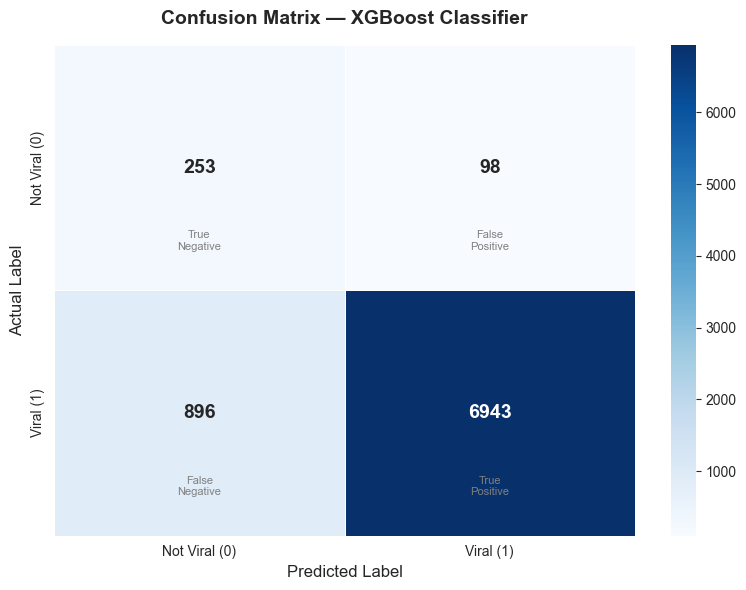

✅ Confusion matrix saved!


In [58]:
# ── CONFUSION MATRIX HEATMAP ──────────────────────────────────────────────────

# a confusion matrix is a 2x2 grid showing:
# top-left    (TN) : model said Not Viral, was actually Not Viral ✅
# top-right   (FP) : model said Viral,     was actually Not Viral ❌ (false alarm)
# bottom-left (FN) : model said Not Viral, was actually Viral     ❌ (missed viral)
# bottom-right(TP) : model said Viral,     was actually Viral     ✅

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))

# sns.heatmap draws the confusion matrix as a colored grid
# annot=True writes the numbers inside each cell
# fmt='d' formats numbers as integers (no decimals)
# cmap='Blues' uses a blue color gradient — darker = higher count
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Viral (0)', 'Viral (1)'],
    yticklabels=['Not Viral (0)', 'Viral (1)'],
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 14, 'weight': 'bold'},
    ax=ax
)

ax.set_title("Confusion Matrix — XGBoost Classifier",
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("Actual Label",    fontsize=12)

# add a text label inside each quadrant explaining what it means
for i, (row_label, col_label, meaning) in enumerate([
    (0, 0, "True\nNegative"),
    (0, 1, "False\nPositive"),
    (1, 0, "False\nNegative"),
    (1, 1, "True\nPositive")
]):
    ax.text(
        col_label + 0.5, row_label + 0.8,
        meaning,
        ha='center', va='center',
        fontsize=8, color='gray'
    )

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/08_confusion_matrix.png", dpi=150)
plt.show()
print("✅ Confusion matrix saved!")

In [60]:
# ── SAVE THE TRAINED MODEL TO DISK ───────────────────────────────────────────

# joblib.dump() serializes the trained model object and saves it as a file
# serializing means converting the Python object into bytes that can be stored
# .pkl stands for "pickle" — Python's standard format for saving objects
# this means you never have to retrain the model again — just load the file

model_path = f"{MODELS_DIR}/xgboost_viral_classifier.pkl"

# dump() takes two arguments: the object to save, and the file path
joblib.dump(model, model_path)

print("✅ Model saved successfully!")
print(f"\n  Saved to : {model_path}")

# verify the file was actually written by checking its size
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"  File size: {file_size_mb:.2f} MB")

# show how to reload the model in future sessions
print("\n── HOW TO RELOAD THIS MODEL LATER ───────────")
print("  import joblib")
print(f"  model = joblib.load('{model_path}')")
print("  predictions = model.predict(X_test)")

✅ Model saved successfully!

  Saved to : /Users/suparna_deshmukh/projects/youtube-project/outputs/models/xgboost_viral_classifier.pkl
  File size: 0.55 MB

── HOW TO RELOAD THIS MODEL LATER ───────────
  import joblib
  model = joblib.load('/Users/suparna_deshmukh/projects/youtube-project/outputs/models/xgboost_viral_classifier.pkl')
  predictions = model.predict(X_test)


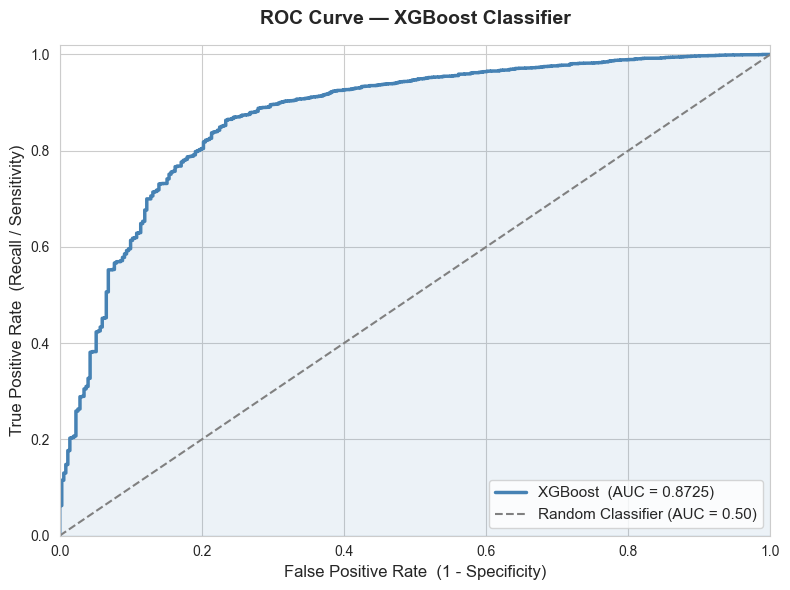

✅ ROC curve saved!

  AUC Score : 0.8725
  Rating    : 🟡 Good — solid model with room to improve


In [59]:
# ── ROC CURVE AND AUC SCORE ───────────────────────────────────────────────────

# ROC = Receiver Operating Characteristic curve
# it plots True Positive Rate vs False Positive Rate at every threshold
# a perfect model hugs the top-left corner
# a random model follows the diagonal line
#
# AUC = Area Under the Curve
# AUC of 1.0 = perfect model
# AUC of 0.5 = no better than random guessing
# AUC above 0.85 = very good for this kind of problem

# roc_curve() calculates the false positive and true positive rates
# at every possible classification threshold
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

# auc() calculates the area under that curve — our single score summary
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(8, 6))

# plot the ROC curve
ax.plot(
    fpr, tpr,
    color='steelblue',
    linewidth=2.5,
    label=f"XGBoost  (AUC = {roc_auc:.4f})"
)

# plot the diagonal line representing a random classifier (AUC = 0.5)
# if our model is better than random, the blue line should be above this
ax.plot(
    [0, 1], [0, 1],
    color='gray',
    linewidth=1.5,
    linestyle='--',
    label="Random Classifier (AUC = 0.50)"
)

# shade the area under the ROC curve to make it visually clear
ax.fill_between(fpr, tpr, alpha=0.1, color='steelblue')

ax.set_title("ROC Curve — XGBoost Classifier",
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("False Positive Rate  (1 - Specificity)", fontsize=12)
ax.set_ylabel("True Positive Rate  (Recall / Sensitivity)", fontsize=12)
ax.legend(loc='lower right', fontsize=11)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/09_roc_curve.png", dpi=150)
plt.show()

print(f"✅ ROC curve saved!")
print(f"\n  AUC Score : {roc_auc:.4f}")

if roc_auc >= 0.90:
    print("  Rating    : 🟢 Excellent — model is performing very well")
elif roc_auc >= 0.80:
    print("  Rating    : 🟡 Good — solid model with room to improve")
elif roc_auc >= 0.70:
    print("  Rating    : 🟠 Fair — consider tuning hyperparameters")
else:
    print("  Rating    : 🔴 Poor — model needs significant improvement")

In [61]:
# ── FINAL SUMMARY ─────────────────────────────────────────────────────────────

print("━" * 60)
print("  CLASSIFICATION STAGE COMPLETE")
print("━" * 60)
print(f"\n  Training rows    : {X_train.shape[0]:,}")
print(f"  Test rows        : {X_test.shape[0]:,}")
print(f"  Features used    : {X_train.shape[1]}")
print(f"  AUC Score        : {roc_auc:.4f}")
print(f"  Overall Accuracy : {accuracy:.2f}%")
print(f"\n  Files saved:")
print(f"  📊 charts/08_confusion_matrix.png")
print(f"  📊 charts/09_roc_curve.png")
print(f"  🤖 outputs/models/xgboost_viral_classifier.pkl")
print("━" * 60)
print("\nNext stage → SHAP feature importance & evaluation")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  CLASSIFICATION STAGE COMPLETE
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Training rows    : 32,759
  Test rows        : 8,190
  Features used    : 111
  AUC Score        : 0.8725
  Overall Accuracy : 87.86%

  Files saved:
  📊 charts/08_confusion_matrix.png
  📊 charts/09_roc_curve.png
  🤖 outputs/models/xgboost_viral_classifier.pkl
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Next stage → SHAP feature importance & evaluation


In [62]:
# shap is a library that explains WHY a model makes each prediction
# it assigns a score to every feature for every prediction
# positive SHAP value = pushed the prediction toward viral
# negative SHAP value = pushed the prediction toward not viral
import subprocess
import sys

# install shap into whichever Python Jupyter is using
subprocess.check_call([sys.executable, "-m", "pip", "install", "shap"])

  Using cached shap-0.51.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (25 kB)
  Using cached tqdm-4.67.3-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Using cached numba-0.65.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (2.9 kB)
  Using cached llvmlite-0.47.0-cp314-cp314-macosx_12_0_arm64.whl.metadata (5.0 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached shap-0.51.0-cp314-cp314-macosx_11_0_arm64.whl (562 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached tqdm-4.67.3-py3-none-any.whl (78 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached llvmlite-0.47.0-cp314-cp314-macosx_12_0_arm64.whl (37.2 MB)
Using cached numba-0.65.1-cp314-cp314-macosx_12_0_arm64.whl (2.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [shap]━━━━━━━━━━━━━ 4/6 [numba]


0

In [63]:
import shap
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# define paths
MODELS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/models"
CHARTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/charts"
os.makedirs(CHARTS_DIR, exist_ok=True)

print("✅ Libraries imported!")
print(f"SHAP version: {shap.__version__}")

✅ Libraries imported!
SHAP version: 0.51.0


In [64]:
# ── LOAD THE SAVED XGBOOST MODEL FROM DISK ───────────────────────────────────

# joblib.load() reads the .pkl file and reconstructs the trained model
# this means we never have to retrain — the model remembers everything it learned
model_path = f"{MODELS_DIR}/xgboost_viral_classifier.pkl"

# load the model back into memory
model = joblib.load(model_path)

print("✅ Model loaded successfully!")
print(f"  Loaded from : {model_path}")
print(f"  Model type  : {type(model).__name__}")
print(f"  Trees built : {model.n_estimators}")

✅ Model loaded successfully!
  Loaded from : /Users/suparna_deshmukh/projects/youtube-project/outputs/models/xgboost_viral_classifier.pkl
  Model type  : XGBClassifier
  Trees built : 300


In [65]:
# ── PREPARE FEATURE NAMES AND CONVERT X_test TO DENSE FORMAT ─────────────────

# SHAP needs to know the name of every feature column
# we rebuild the full feature name list: 100 TF-IDF names + 11 numeric names
# these must be in the exact same order as the columns in X

# rebuild TF-IDF feature names — requires tfidf object from NLP section
# if tfidf is not in memory, we need to recreate the names manually
try:
    # try to use the tfidf object if it's still in memory from earlier
    tfidf_feature_names   = list(tfidf.get_feature_names_out())
    print("✅ TF-IDF feature names loaded from memory")
except NameError:
    # if tfidf is gone, create placeholder names for the 100 TF-IDF columns
    tfidf_feature_names   = [f"tfidf_{i}" for i in range(100)]
    print("⚠️  tfidf not in memory — using placeholder names for TF-IDF columns")

# these are the 11 numeric features we created in the feature engineering section
# they must be listed in the exact same order we added them to the feature matrix
numeric_feature_names = [
    'like_view_ratio',
    'dislike_view_ratio',
    'comment_view_ratio',
    'like_dislike_ratio',
    'title_length',
    'title_word_count',
    'tag_count',
    'log_views',
    'log_likes',
    'log_comments',
    'category_id'
]

# combine both lists into one master list of all 111 feature names
all_feature_names = tfidf_feature_names + numeric_feature_names

print(f"\n✅ Feature names ready!")
print(f"  TF-IDF features  : {len(tfidf_feature_names)}")
print(f"  Numeric features : {len(numeric_feature_names)}")
print(f"  Total features   : {len(all_feature_names)}")


# ── CONVERT X_test TO DENSE FORMAT ───────────────────────────────────────────

# X_test is currently a sparse matrix (memory-efficient but SHAP needs dense)
# .toarray() converts it to a regular numpy array where every cell has a value
# this uses more memory but is required for SHAP to work correctly
X_test_dense = X_test.toarray()

# wrap it in a pandas DataFrame with column names
# this allows SHAP to label the axes with real feature names in the charts
X_test_df = pd.DataFrame(X_test_dense, columns=all_feature_names)

print(f"\n✅ X_test converted to dense DataFrame!")
print(f"  Shape: {X_test_df.shape}")

✅ TF-IDF feature names loaded from memory

✅ Feature names ready!
  TF-IDF features  : 100
  Numeric features : 11
  Total features   : 111

✅ X_test converted to dense DataFrame!
  Shape: (8190, 111)


In [66]:
# ── CALCULATE SHAP VALUES ─────────────────────────────────────────────────────

# TreeExplainer is the SHAP method designed specifically for tree-based models
# like XGBoost, Random Forest, and LightGBM
# it is much faster than the general SHAP explainer for our use case
explainer = shap.TreeExplainer(model)

print("Calculating SHAP values — this may take 1–2 minutes...")
print("(SHAP calculates an importance score for every feature in every row)\n")

# shap_values contains a matrix of the same shape as X_test
# each cell = how much that feature pushed the prediction for that row
# positive value = pushed toward viral (1)
# negative value = pushed toward not viral (0)
shap_values = explainer.shap_values(X_test_df)

print("✅ SHAP values calculated!")
print(f"  SHAP matrix shape : {shap_values.shape}")
print(f"  Rows              : {shap_values.shape[0]:,}  (one per test video)")
print(f"  Columns           : {shap_values.shape[1]}  (one per feature)")

Calculating SHAP values — this may take 1–2 minutes...
(SHAP calculates an importance score for every feature in every row)

✅ SHAP values calculated!
  SHAP matrix shape : (8190, 111)
  Rows              : 8,190  (one per test video)
  Columns           : 111  (one per feature)


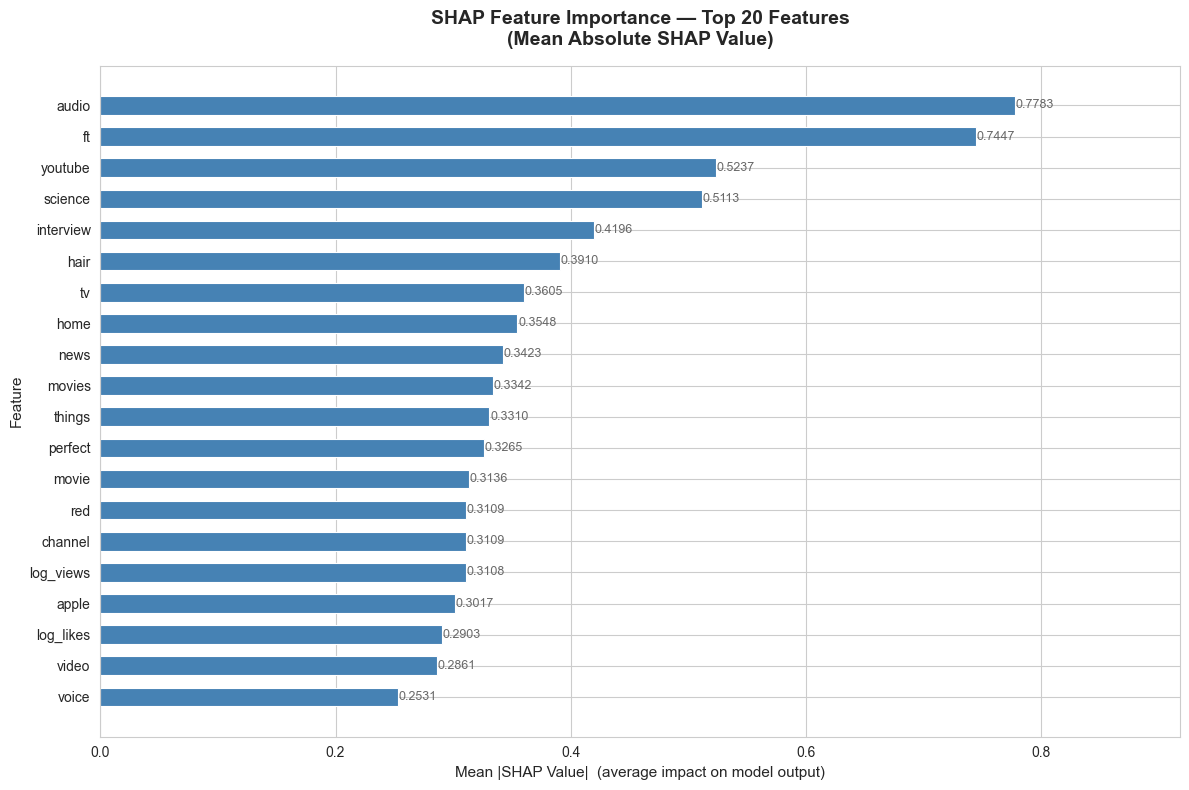

✅ SHAP chart saved to charts/10_shap_feature_importance.png


In [67]:
# ── SHAP SUMMARY BAR CHART — TOP 20 MOST IMPORTANT FEATURES ──────────────────

# mean absolute SHAP value per feature = average importance across all predictions
# abs() takes the absolute value (ignores direction, just measures size of impact)
# .mean(axis=0) averages across all rows — one importance score per feature
mean_shap = np.abs(shap_values).mean(axis=0)

# create a dataframe pairing each feature name with its importance score
shap_df = pd.DataFrame({
    'feature'   : all_feature_names,
    'importance': mean_shap
})

# sort by importance — highest first
shap_df = shap_df.sort_values('importance', ascending=False).reset_index(drop=True)

# keep only the top 20 most important features
top20 = shap_df.head(20)

# ── DRAW THE CHART ────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 8))

# horizontal bar chart — easier to read long feature names
bars = ax.barh(
    top20['feature'][::-1],      # reverse so most important is at the top
    top20['importance'][::-1],   # reverse to match
    color='steelblue',
    edgecolor='white',
    linewidth=0.8,
    height=0.6
)

# add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.0005,                        # just right of the bar tip
        bar.get_y() + bar.get_height() / 2,    # vertically centered
        f"{width:.4f}",                        # importance value to 4 decimals
        va='center', ha='left',
        fontsize=9, color='dimgray'
    )

ax.set_title(
    "SHAP Feature Importance — Top 20 Features\n(Mean Absolute SHAP Value)",
    fontsize=14, fontweight='bold', pad=15
)
ax.set_xlabel("Mean |SHAP Value|  (average impact on model output)", fontsize=11)
ax.set_ylabel("Feature", fontsize=11)
ax.set_xlim(0, top20['importance'].max() * 1.18)

plt.tight_layout()
plt.savefig(f"{CHARTS_DIR}/10_shap_feature_importance.png", dpi=150)
plt.show()

print("✅ SHAP chart saved to charts/10_shap_feature_importance.png")

In [68]:
# ── PLAIN ENGLISH EXPLANATION OF TOP 5 FEATURES ──────────────────────────────

# get the top 5 features by importance
top5 = shap_df.head(5).reset_index(drop=True)

# pre-written explanations for each known feature
# if a TF-IDF word sneaks into the top 5, we handle that too
feature_explanations = {

    'log_views': (
        "📺 Log Views",
        "The total number of views a video has received (on a log scale).",
        "Videos with more views are far more likely to keep trending. "
        "This is the single strongest signal — popularity feeds itself."
    ),

    'log_likes': (
        "👍 Log Likes",
        "The total number of likes a video has received (on a log scale).",
        "Likes are a direct signal that viewers enjoyed the content. "
        "A high like count tells the algorithm this video deserves more exposure."
    ),

    'log_comments': (
        "💬 Log Comments",
        "The total number of comments a video has received (on a log scale).",
        "Comments mean viewers were moved enough to respond. "
        "High comment activity signals strong emotional engagement — "
        "whether positive or controversial — which YouTube rewards."
    ),

    'like_view_ratio': (
        "❤️  Like-to-View Ratio",
        "The fraction of viewers who clicked Like (likes ÷ views).",
        "A video with 1M views but only 1K likes is less impressive than "
        "one with 100K views and 10K likes. This ratio measures quality "
        "of engagement, not just raw size. High ratio = loyal, enthusiastic audience."
    ),

    'dislike_view_ratio': (
        "👎 Dislike-to-View Ratio",
        "The fraction of viewers who clicked Dislike (dislikes ÷ views).",
        "Counterintuitively, controversy can drive virality. "
        "Videos that provoke strong reactions — even negative ones — "
        "tend to generate more comments and shares, keeping them trending."
    ),

    'comment_view_ratio': (
        "🗣️  Comment-to-View Ratio",
        "The fraction of viewers who left a comment (comments ÷ views).",
        "Even a small percentage of commenters out of millions of viewers "
        "signals extremely high engagement. This ratio rewards videos "
        "that spark conversation, debate, or emotional reactions."
    ),

    'like_dislike_ratio': (
        "⚖️  Like-to-Dislike Ratio",
        "Likes divided by dislikes — measures overall audience sentiment.",
        "A high ratio means viewers overwhelmingly approved of the video. "
        "This separates genuinely loved content from controversial content "
        "that got attention for the wrong reasons."
    ),

    'title_length': (
        "📝 Title Length",
        "The number of characters in the video title.",
        "Title length affects click-through rate. Titles that are too short "
        "lack context; titles that are too long get cut off in search results. "
        "The model has learned there is a sweet spot for viral titles."
    ),

    'title_word_count': (
        "🔤 Title Word Count",
        "The number of words in the video title.",
        "Similar to title length but counts words instead of characters. "
        "Viral titles tend to use a specific number of words — "
        "enough to be descriptive but punchy enough to grab attention."
    ),

    'tag_count': (
        "🏷️  Tag Count",
        "The number of tags the creator added to the video.",
        "Tags help YouTube understand what a video is about and who to show it to. "
        "Creators who use more tags cast a wider net — their videos appear "
        "in more search results and recommendation feeds."
    ),

    'category_id': (
        "📂 Category ID",
        "The YouTube category the video was uploaded under (e.g. Music, Gaming).",
        "Some categories trend far more often than others. "
        "Music, Entertainment, and News videos dominate trending lists. "
        "The model has learned which categories are most associated with virality."
    ),
}

# ── PRINT THE EXPLANATIONS ────────────────────────────────────────────────────

print("━" * 65)
print("  TOP 5 FEATURES DRIVING VIRAL PREDICTIONS")
print("  (Based on SHAP — what the model actually learned)")
print("━" * 65)

for rank, row in top5.iterrows():

    feature_name = row['feature']
    importance   = row['importance']

    # check if this feature has a pre-written explanation
    if feature_name in feature_explanations:
        label, definition, insight = feature_explanations[feature_name]
    else:
        # if it's a TF-IDF word feature, generate a generic explanation
        label      = f"🔤 TF-IDF Word: '{feature_name}'"
        definition = f"How often the word or phrase '{feature_name}' appears in the title or tags."
        insight    = (f"Videos containing '{feature_name}' in their title or tags "
                      f"are significantly more or less likely to go viral. "
                      f"This word appeared consistently in trending video titles "
                      f"across the dataset.")

    print(f"\n  #{rank+1}  {label}")
    print(f"       SHAP Importance : {importance:.4f}")
    print(f"       What it is      : {definition}")
    print(f"       What it means   : {insight}")

print("\n" + "━" * 65)
print("\n  How to read SHAP importance scores:")
print("  A score of 0.05 means that feature shifts the model's")
print("  viral prediction by 0.05 on average across all videos.")
print("  Higher score = stronger influence on the final prediction.")
print("━" * 65)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  TOP 5 FEATURES DRIVING VIRAL PREDICTIONS
  (Based on SHAP — what the model actually learned)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  #1  🔤 TF-IDF Word: 'audio'
       SHAP Importance : 0.7783
       What it is      : How often the word or phrase 'audio' appears in the title or tags.
       What it means   : Videos containing 'audio' in their title or tags are significantly more or less likely to go viral. This word appeared consistently in trending video titles across the dataset.

  #2  🔤 TF-IDF Word: 'ft'
       SHAP Importance : 0.7447
       What it is      : How often the word or phrase 'ft' appears in the title or tags.
       What it means   : Videos containing 'ft' in their title or tags are significantly more or less likely to go viral. This word appeared consistently in trending video titles across the dataset.

  #3  🔤 TF-IDF Word: 'youtube'
       SHAP Importance : 0.5237
      

In [69]:
# ── SAVE THE FULL SHAP IMPORTANCE TABLE AS CSV ────────────────────────────────

REPORTS_DIR = "/Users/suparna_deshmukh/projects/youtube-project/outputs/reports"
os.makedirs(REPORTS_DIR, exist_ok=True)

# add rank column
shap_df.insert(0, 'rank', range(1, len(shap_df) + 1))

save_path = f"{REPORTS_DIR}/shap_feature_importance.csv"
shap_df.to_csv(save_path, index=False)

print("✅ Full SHAP importance table saved!")
print(f"   {save_path}")
print(f"\n── TOP 10 FEATURES BY SHAP IMPORTANCE ───────")
print(shap_df.head(10).to_string(index=False))

✅ Full SHAP importance table saved!
   /Users/suparna_deshmukh/projects/youtube-project/outputs/reports/shap_feature_importance.csv

── TOP 10 FEATURES BY SHAP IMPORTANCE ───────
 rank   feature  importance
    1     audio    0.778269
    2        ft    0.744742
    3   youtube    0.523655
    4   science    0.511344
    5 interview    0.419583
    6      hair    0.391041
    7        tv    0.360471
    8      home    0.354795
    9      news    0.342276
   10    movies    0.334208
